File(s) generated: data/histogram-3.pkl

Assume a "conventional WEC" shape, where successive (h-d) past the region adjacent to the target region are taller.

Do ratios from 4-dependencies: (h-d1)/radwidth1, (h-d0)/(h-d1), (h-d2)/(h-d1), radwidth1/a1, but for a wider range of non-fixed values.

Check for damping: radwidth1/dist_to_e.


In [4]:
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
up2_path = str((HERE / ".." / "..").resolve())
up3_path = str((HERE / ".." / ".." / "..").resolve())
for pathstr in [up2_path, up3_path]:
  if pathstr not in sys.path:
      sys.path.insert(0, pathstr)

from helpers import *
import numpy as np
from numpy import random

import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

file1 = str((HERE / "data" / "histogram-3.pkl").resolve())

In [5]:
# raw data generation / data loading and convergence metrics (file1)

hmdrs = [30]
left_ratios = [0.5, 0.95, 1.05, 1.3]
right_ratios = [0.5, 0.95, 1.05, 1.3]
rad_ratios = [0.1, 0.2]
region_counts = [3]

rho, big_nmk, nmk_max = 1023, 200, 150

def solve_and_store(h, d, a, heaving, NMK, m0, rho, nmk_max, region = 1):
  prob = ConvergenceProblemI(h, d, a, heaving, NMK, m0, rho)
  mk = prob.m_k
  info = {"h" : h,
          "d" : d,
          "a" : a,
          "region" : region,
          "m0s" : [m0]}
  print(info)
  return merge_dicts(info, prob.convergence_study_over_m0s(nmk_max, [m0], [mk]))

def generate_h_d_a_m0_second(hmdr, left_ratio, right_ratio, rad_ratio, region_count):
  hmd1 = random.uniform(low = 0, high = 10)
  hmd0 = left_ratio * hmd1
  hmd2 = right_ratio * hmd1
  radwidth1 = hmd1/hmdr
  radwidth0 = radwidth1/rad_ratio - radwidth1
  radwidth2 = hmd2/random.uniform(low=1, high =10)

  radwidths = [radwidth0, radwidth1, radwidth2]
  hmds = [hmd0, hmd1, hmd2]

  for i in range(3, region_count):
    hmds.append(random.uniform(low = 1.01, high = 3) * hmds[-1])
    radwidths.append(hmds[-1]/random.uniform(low=1, high =10))

  h_min = max(hmds)
  h = random.uniform(low = 1.1 * h_min, high = 3 * h_min)
  m0 = random.uniform(low = 1/h, high = 80/h)
  d = [h-hmd for hmd in hmds]
  a = [sum(radwidths[0:i+1]) for i in range(len(d))]
  for i in range(len(d)):
    assert d[i] > 0
    inner = 0 if i == 0 else a[i-1]
    assert a[i] > inner
  return h, d, a, m0

# all_prob_sets = []
# for region_count in region_counts:
#   heaving, NMK = [region == 1 for region in range(region_count)], [big_nmk] * (region_count + 1)
#   for hmdr in hmdrs:
#     for left_ratio in left_ratios:
#       for right_ratio in right_ratios:
#         for rad_ratio in rad_ratios:
#           prob_set = []
#           for i in range(50):
#             h, d, a, m0 = generate_h_d_a_m0_second(hmdr, left_ratio, right_ratio, rad_ratio, region_count)
#             prob_set.append(solve_and_store(h, d, a, heaving, NMK, m0, rho, nmk_max))
#           all_prob_sets.append(prob_set)
#           update_data_file(all_prob_sets, file1)
#           print("Finished a set.", region_count, hmdr, right_ratio)

hist_prob_sets = open_pkl_file(file1)
for subset in hist_prob_sets:
  generate_convergence_data(subset, [0.01, 0.005])
  generate_log_data(subset)

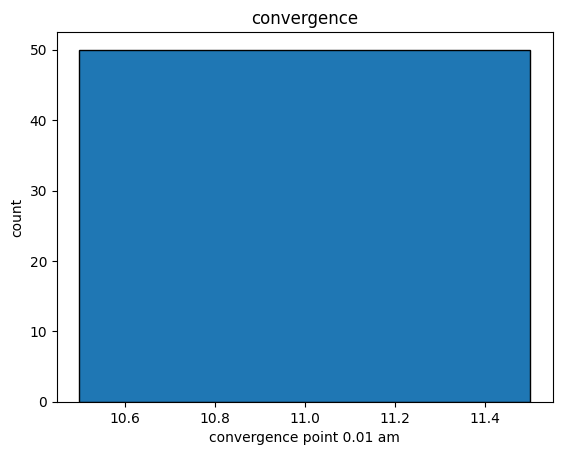

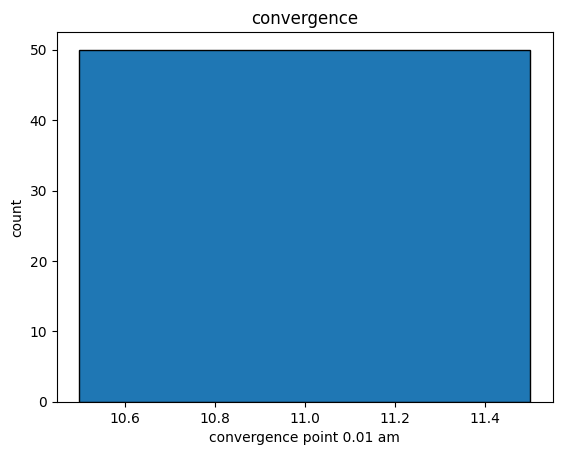

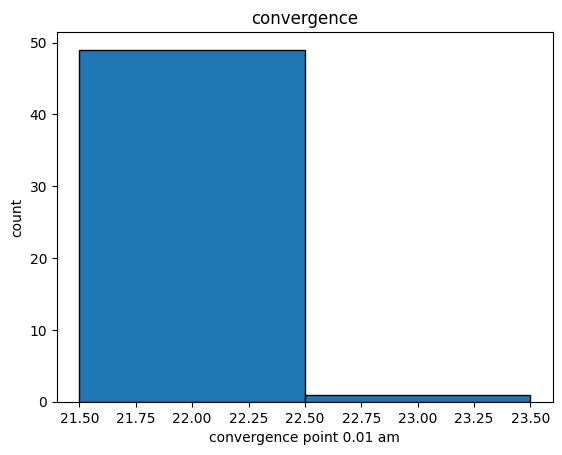

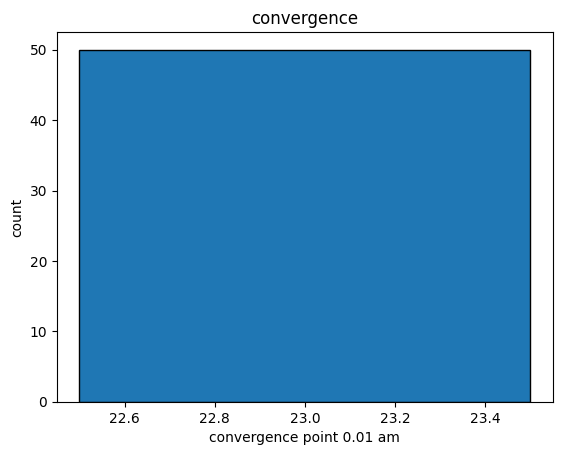

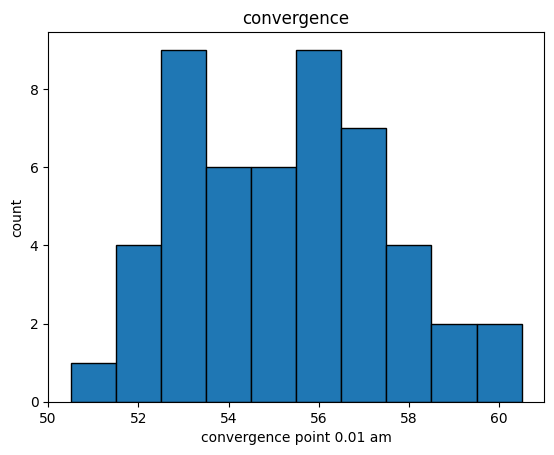

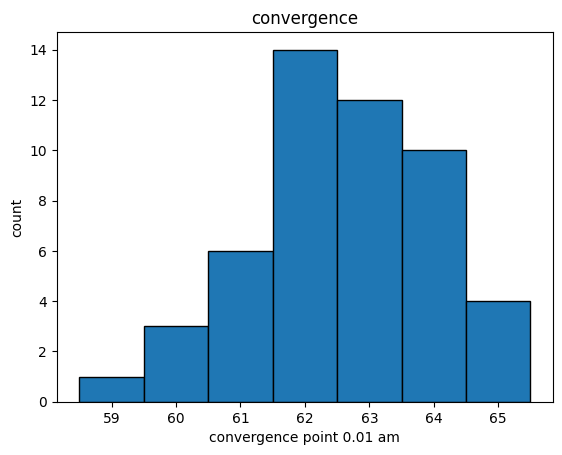

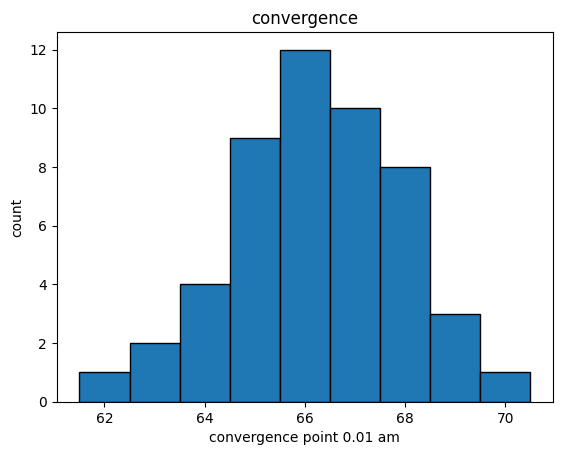

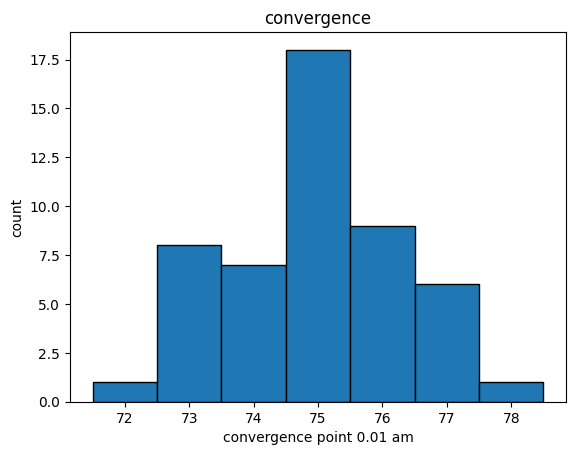

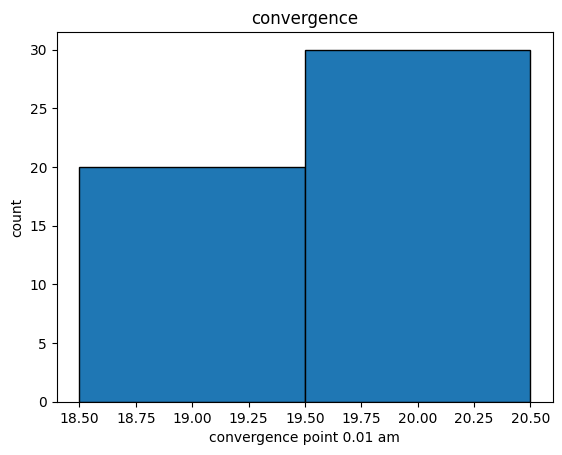

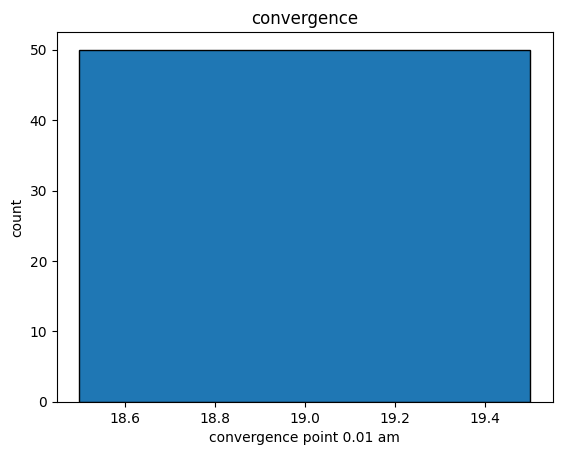

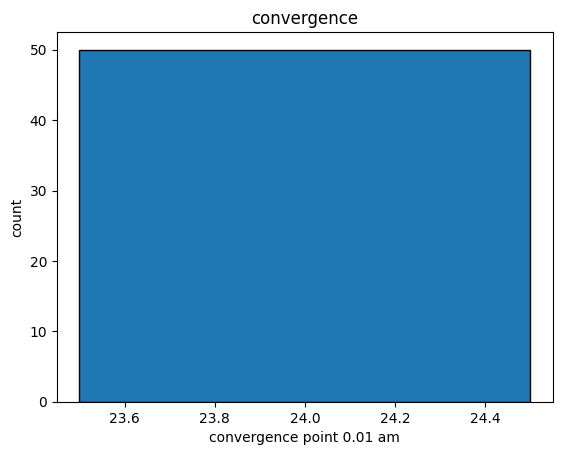

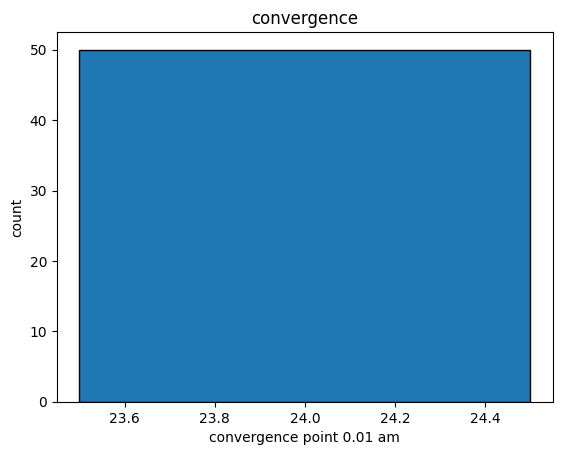

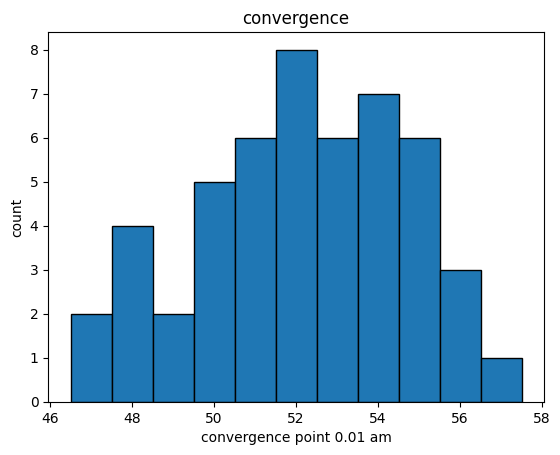

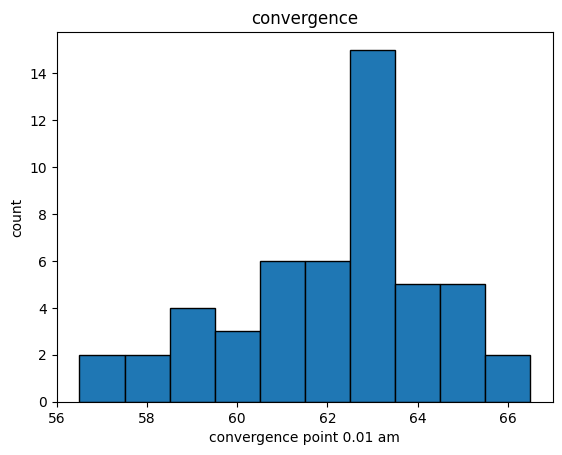

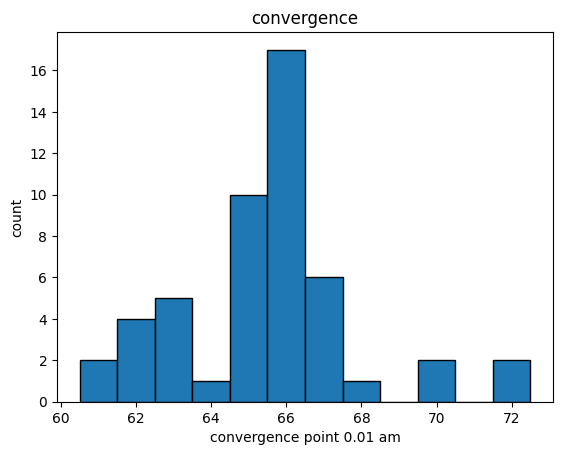

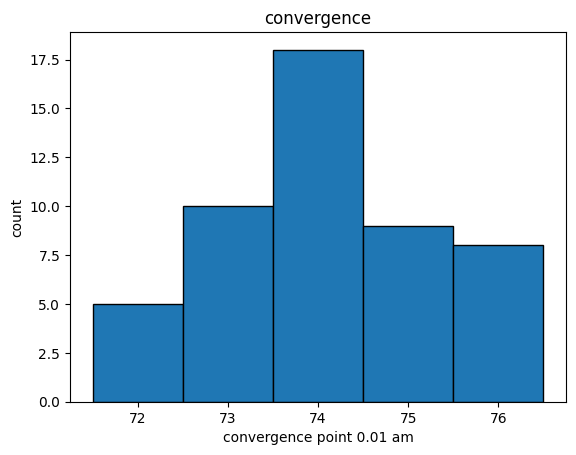

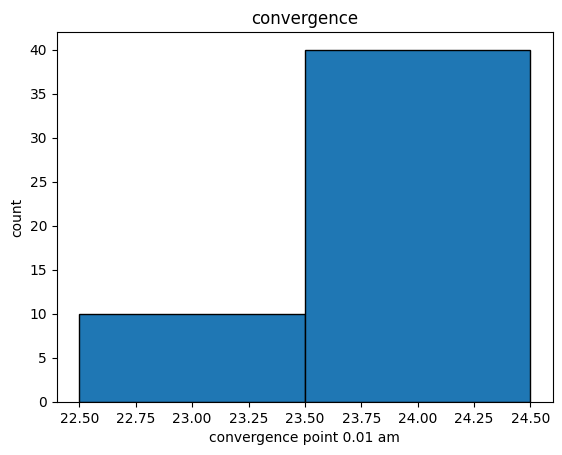

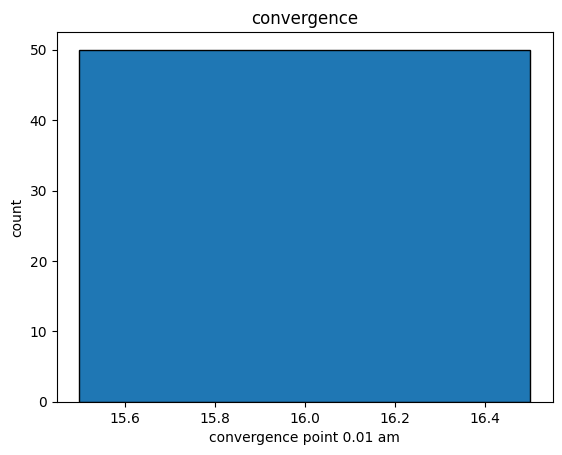

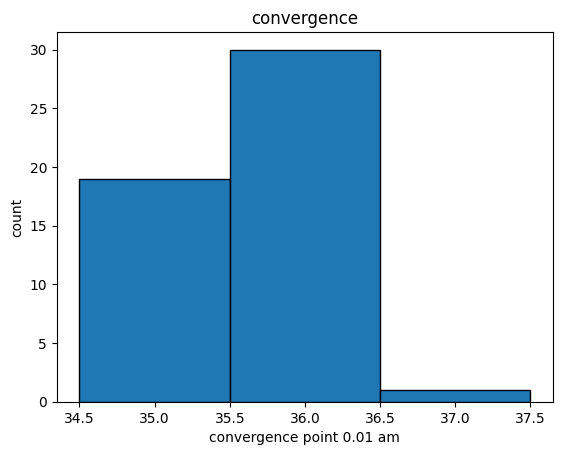

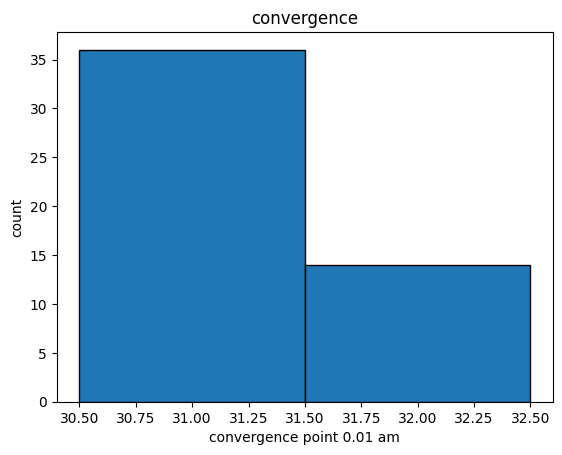

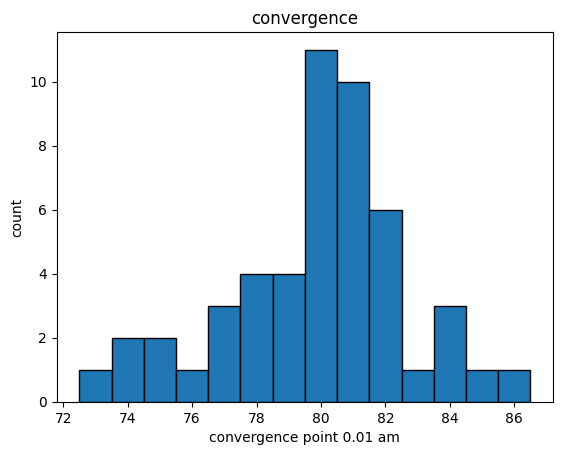

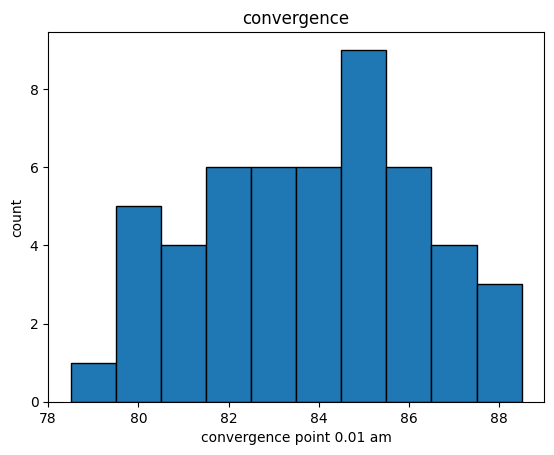

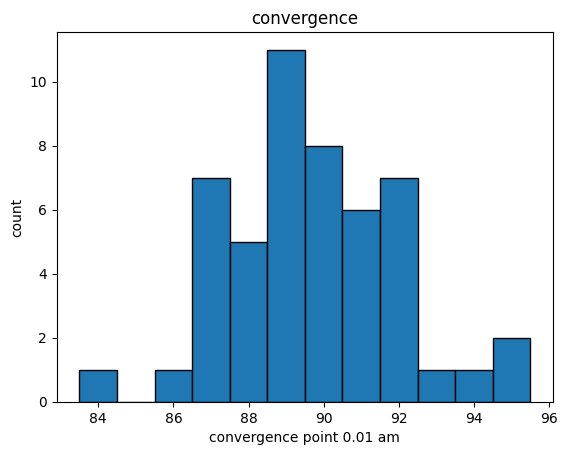

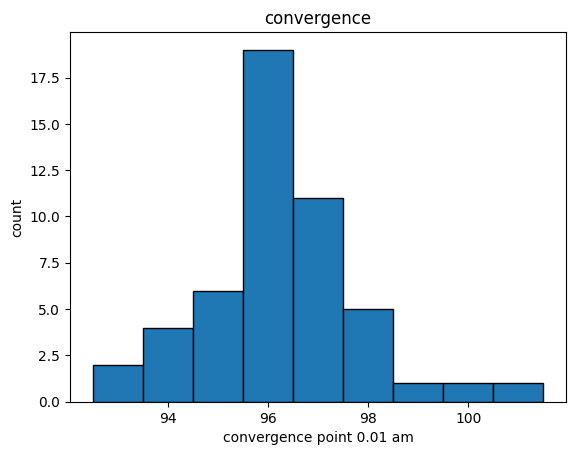

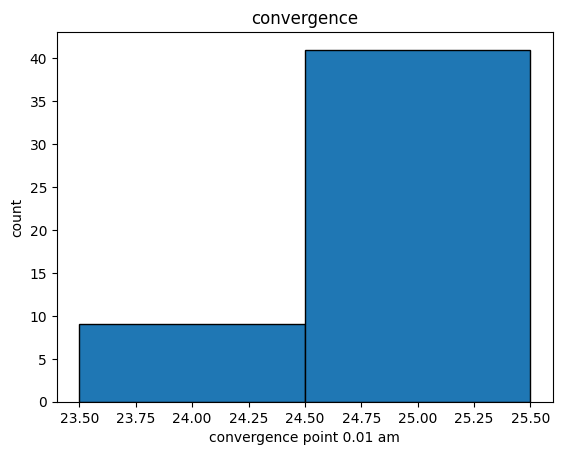

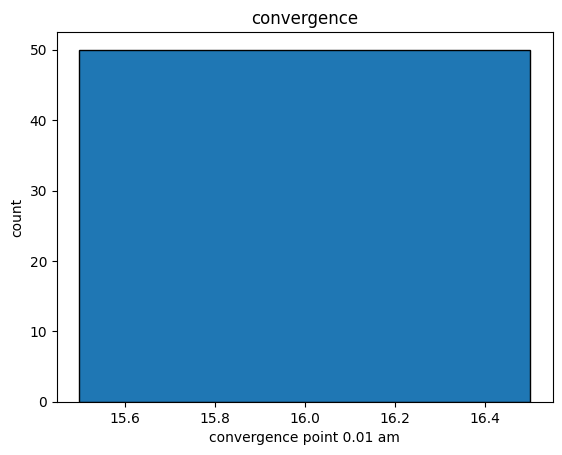

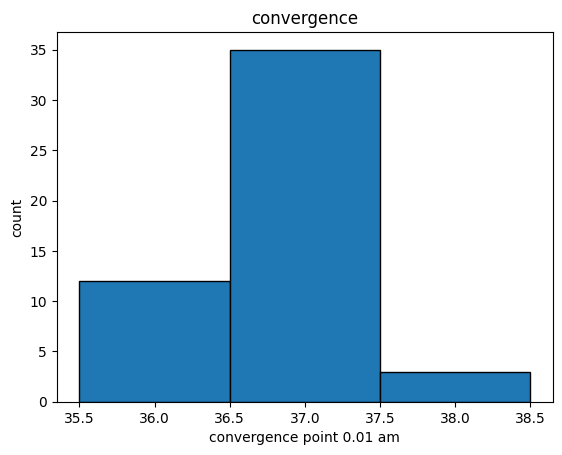

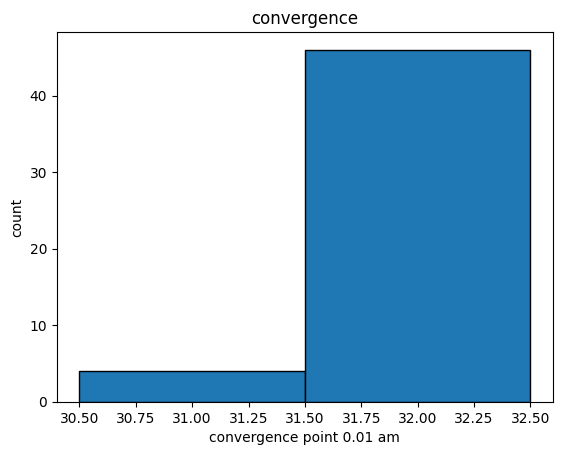

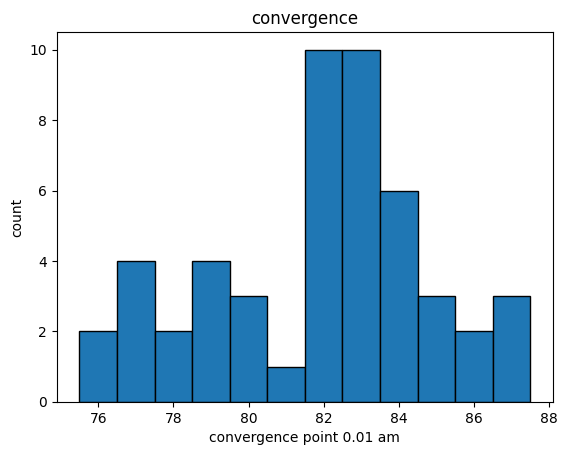

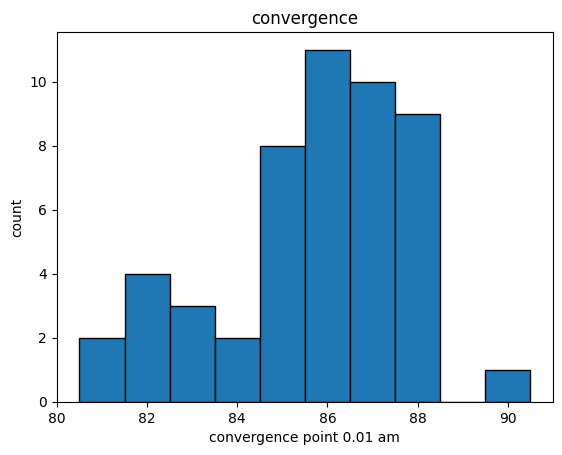

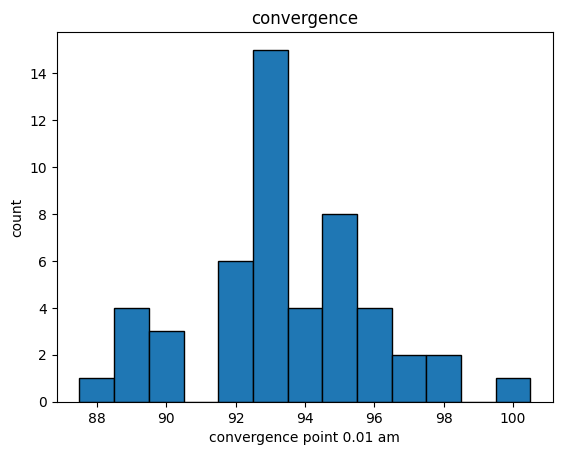

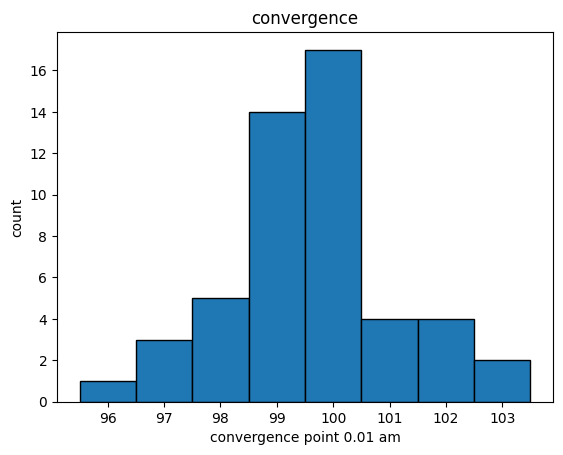

In [ ]:
# added mass histograms
for subset in hist_prob_sets:
  histogram(subset, "am", 0.01)

In [7]:
# Generate a dicionary of ratios.
def hmdi(data_dict, i):
  return data_dict["h"] - data_dict["d"][i]

def di(data_dict, i):
  return data_dict["d"][i]

def radwidthi(data_dict, i):
  return data_dict["a"][i] - (0 if i == 0 else data_dict["a"][i-1])

def radrange(data_dict, i, j):
  return sum([radwidthi(data_dict, k) for k in range(i+1, j + 1)])

dim1s = {"h" : lambda data_dict, m0: data_dict["h"],
        "(1/m0)" : lambda data_dict, m0: 1/m0}

for i in range(3):
  dim1s["d" + str(i)] = lambda data_dict, m0, i=i : di(data_dict, i)
  dim1s["(h-d" + str(i) + ")"] = lambda data_dict, m0, i=i: hmdi(data_dict, i)
  dim1s["radwidth" + str(i)] = lambda data_dict, m0, i=i: radwidthi(data_dict, i)
  dim1s["a" + str(i)] = lambda data_dict, m0, i=i: radrange(data_dict, -1, i)
  for j in range(i + 2, 3):
    dim1s["(a" + str(j) + "-a" + str(i) + ")"] = lambda data_dict, m0, i=i, j=j : radrange(data_dict, i, j)

dim0s = {} # size = 15**2
for key1 in dim1s.keys():
  for key2 in dim1s.keys():
    if key1 == key2:
      pass
    else:
      dim0s[key1 + "/" + key2] = (lambda data_dict, m0, k1 = key1, k2 = key2 : dim1s[k1](data_dict, m0)/dim1s[k2](data_dict, m0))

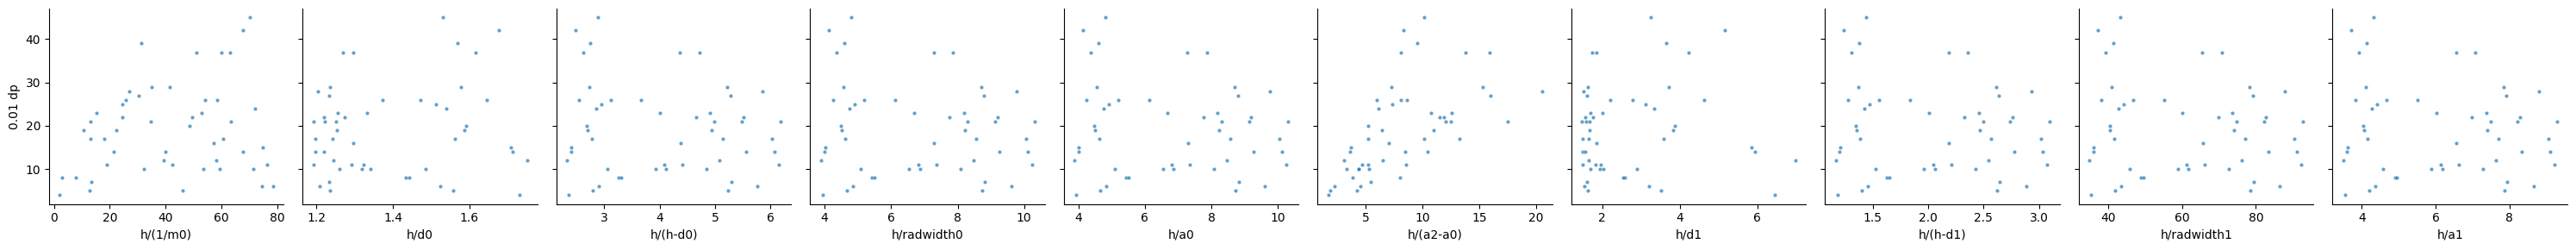

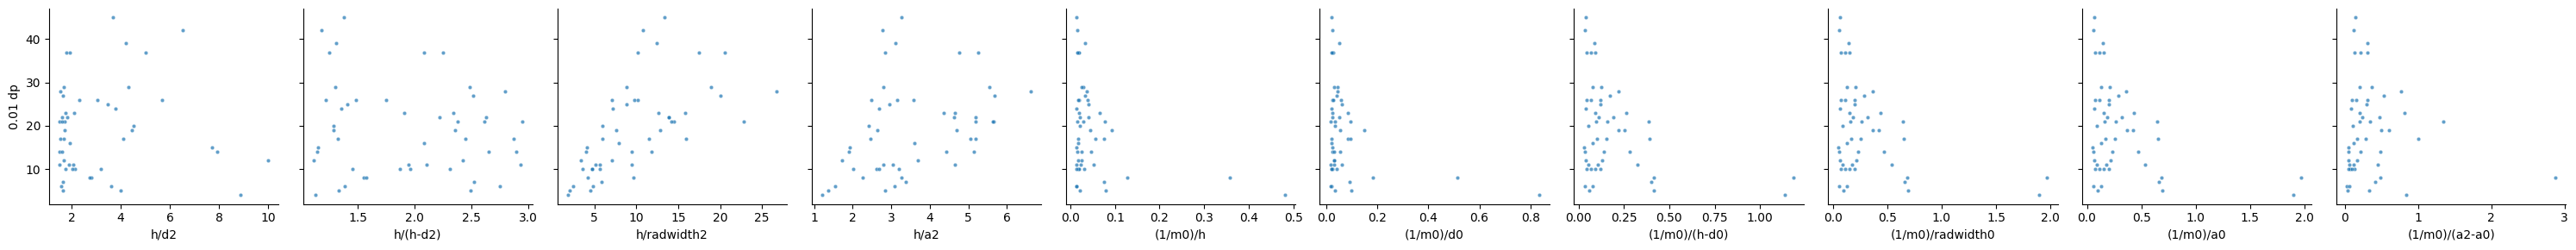

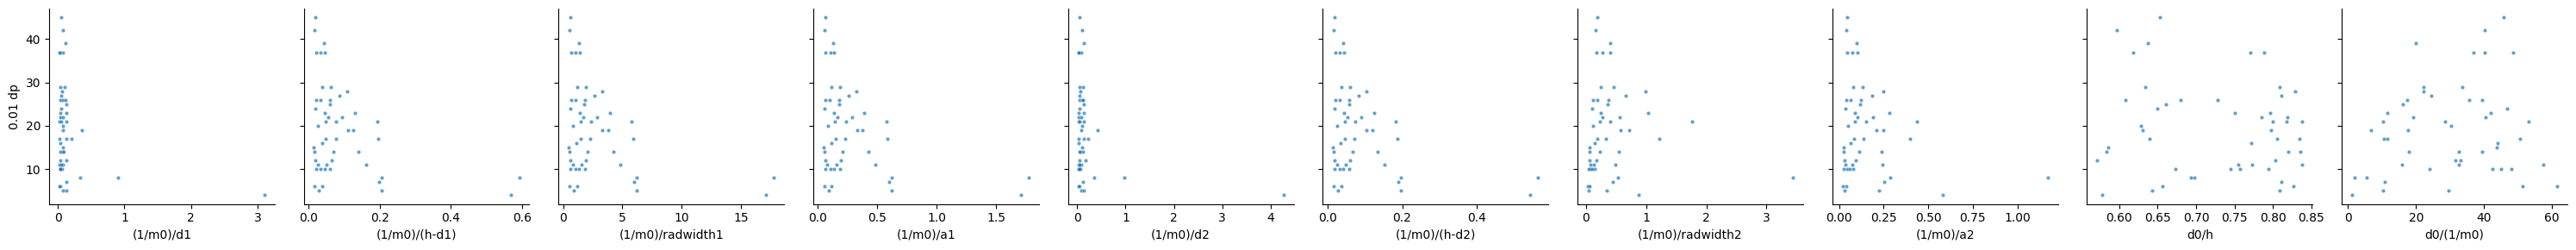

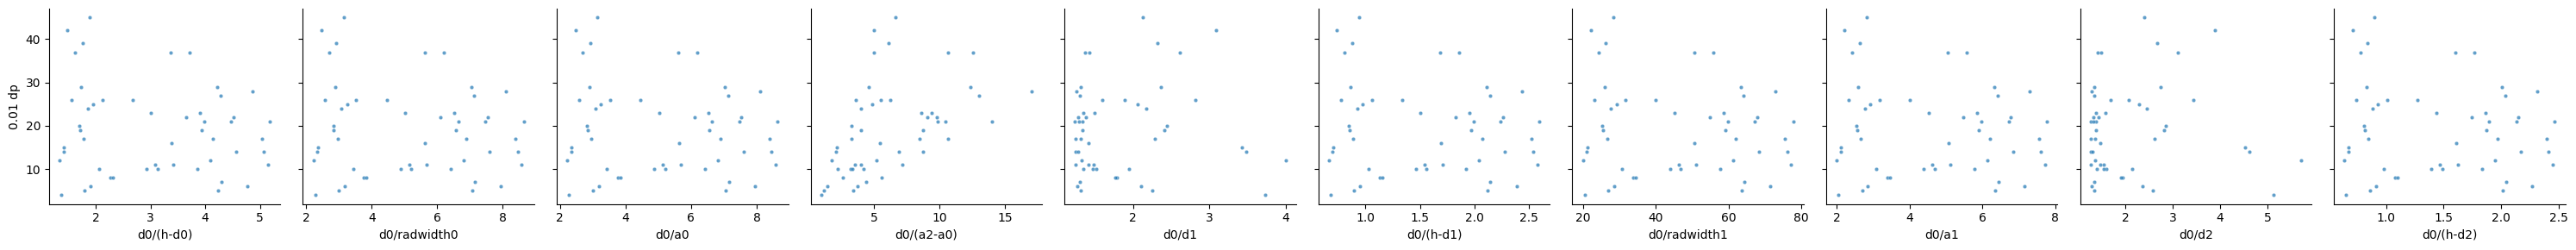

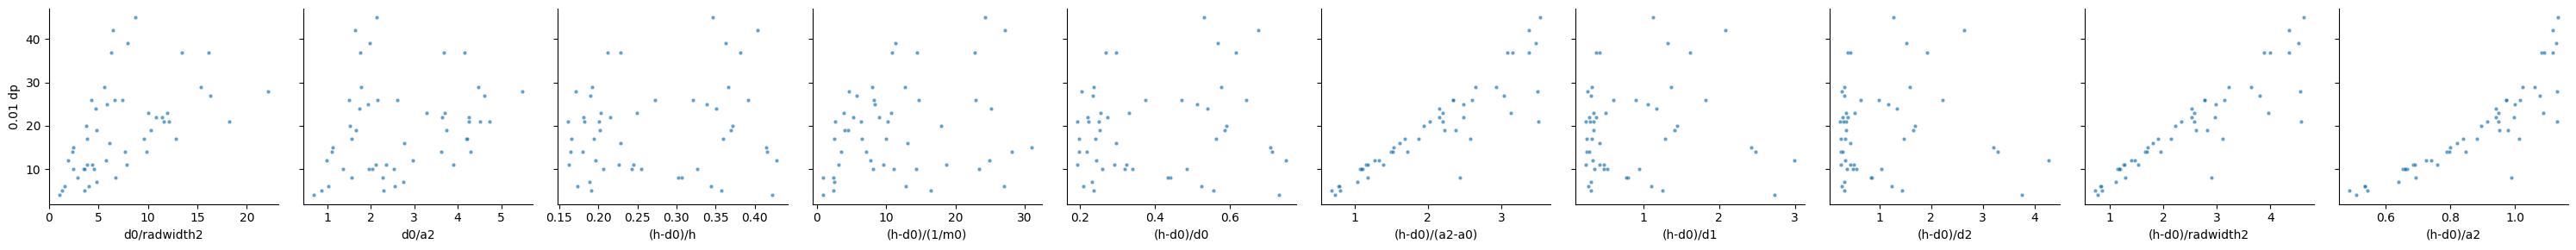

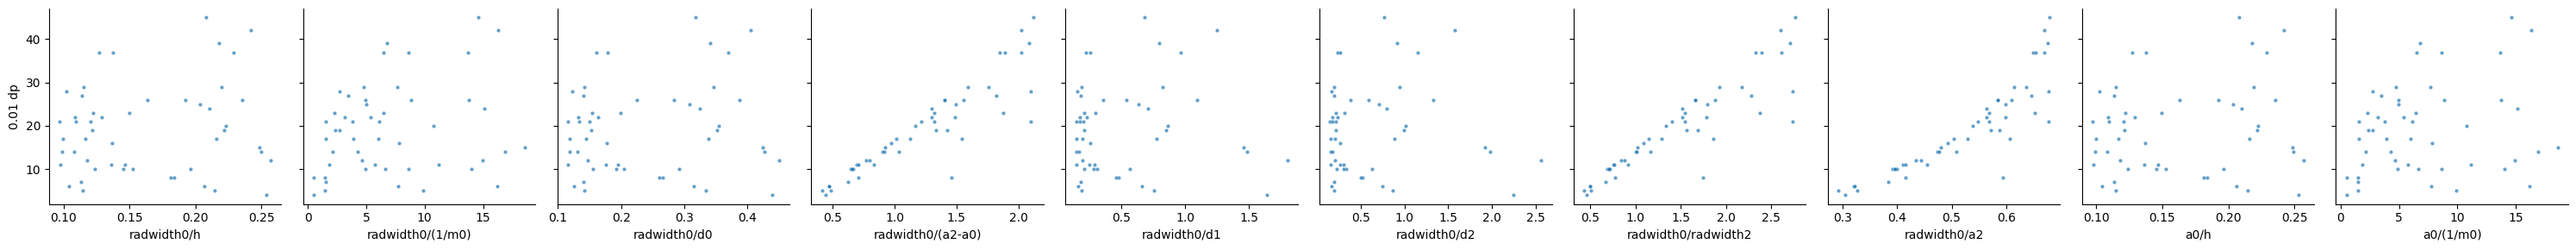

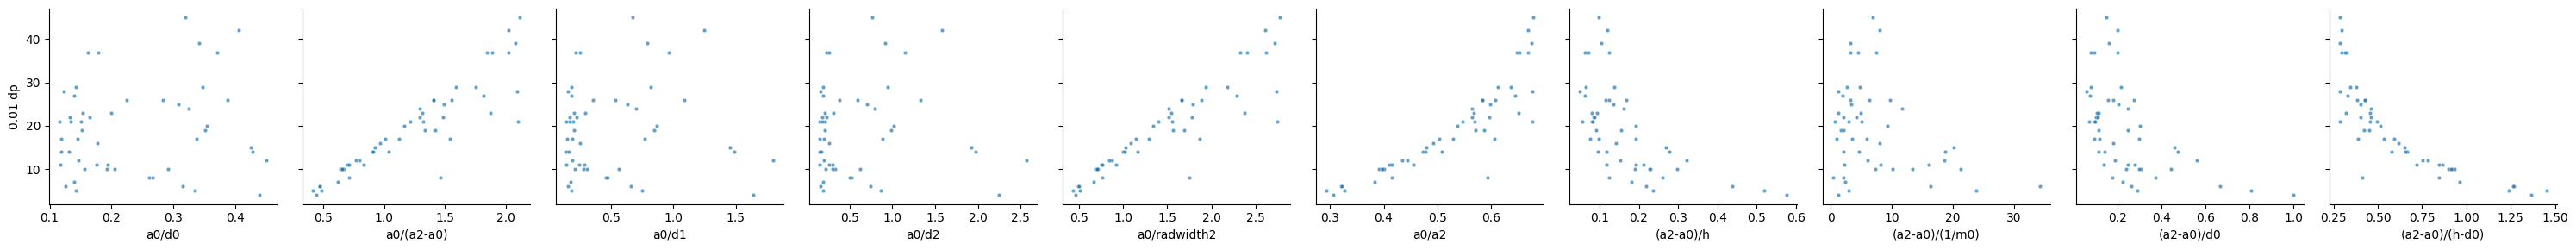

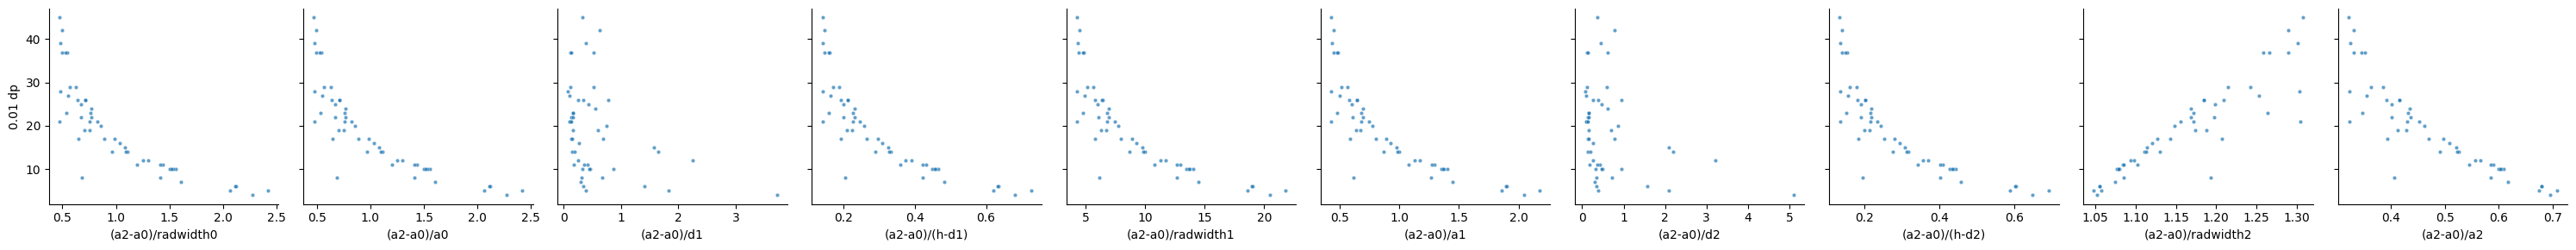

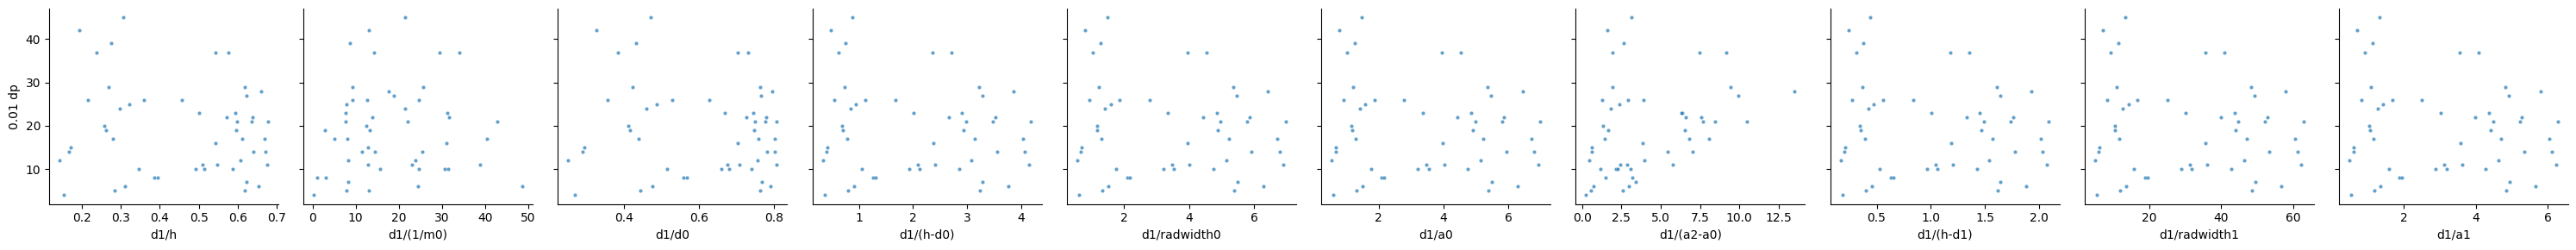

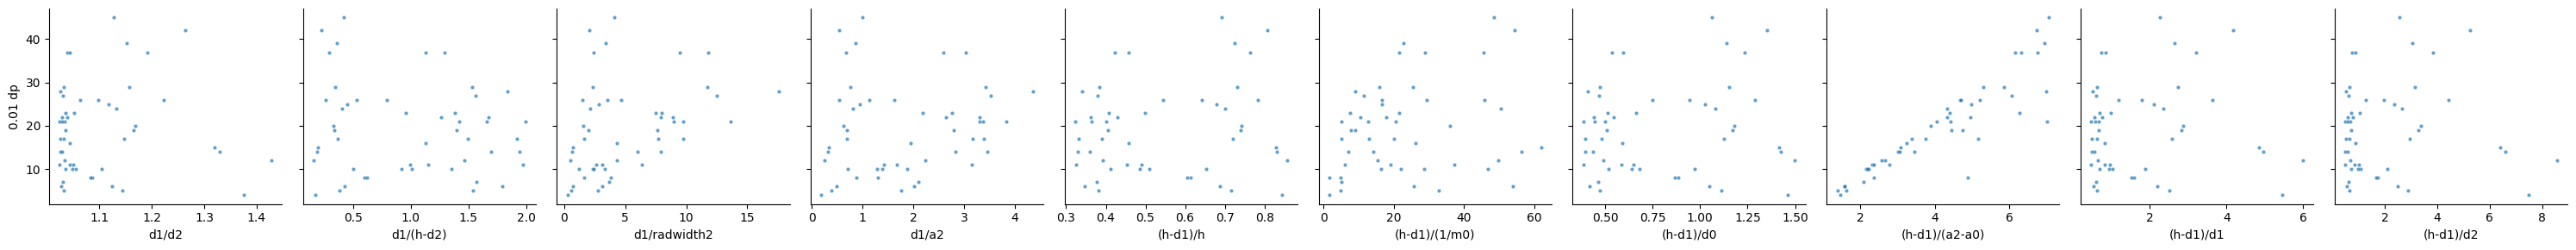

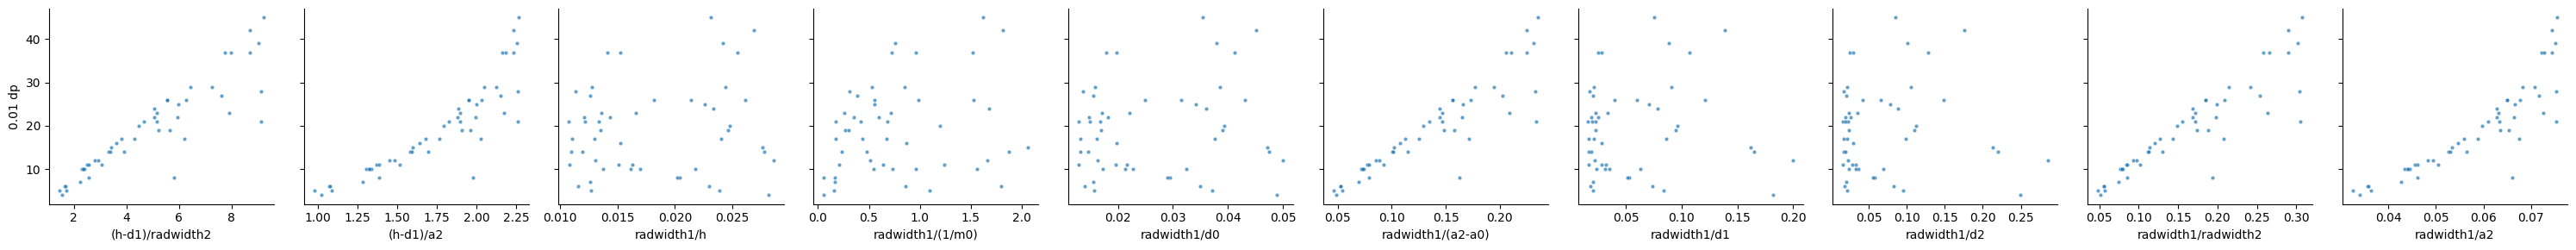

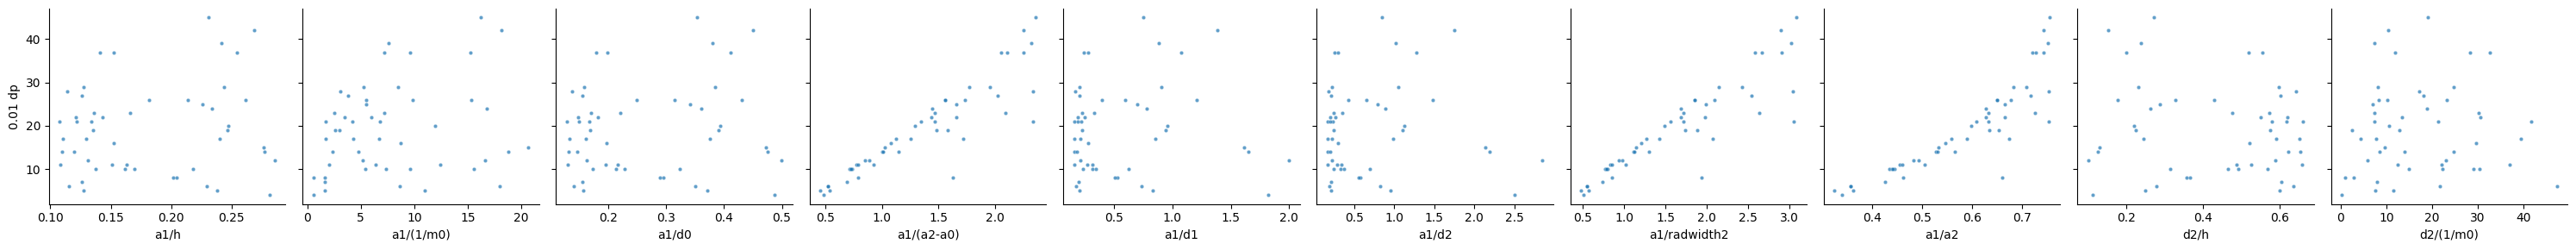

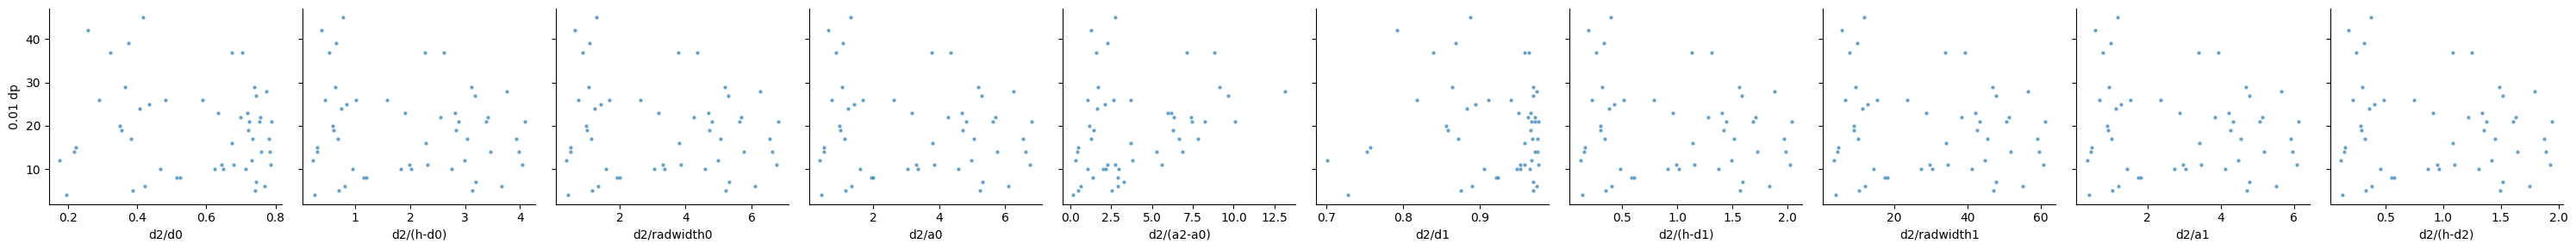

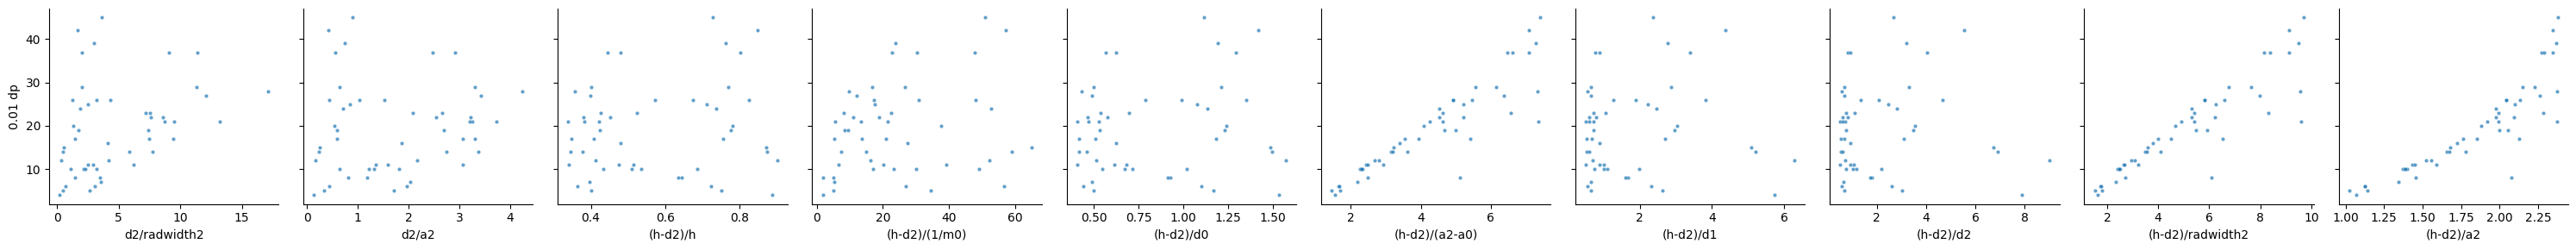

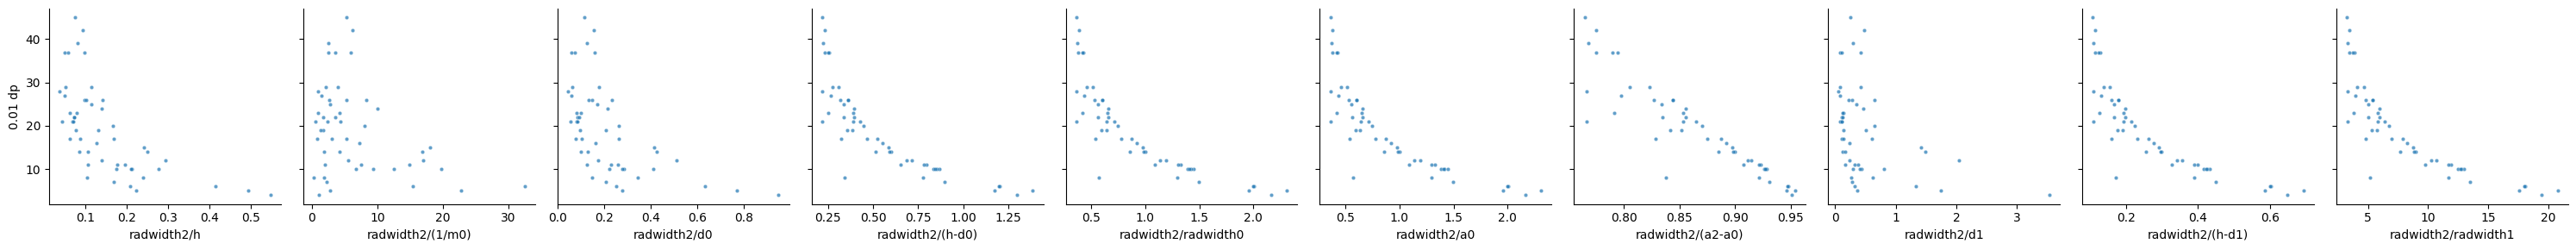

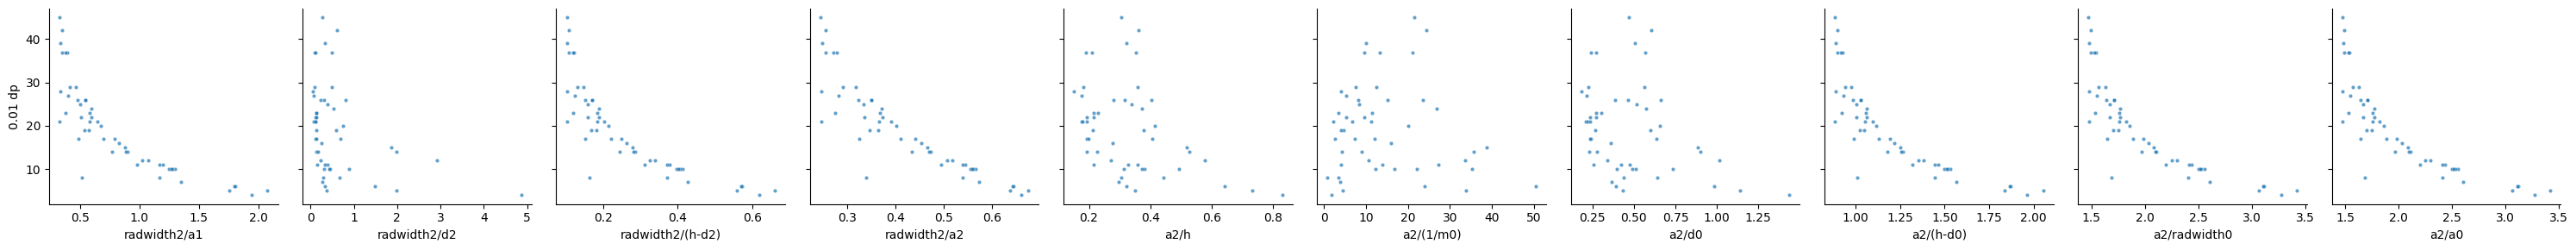

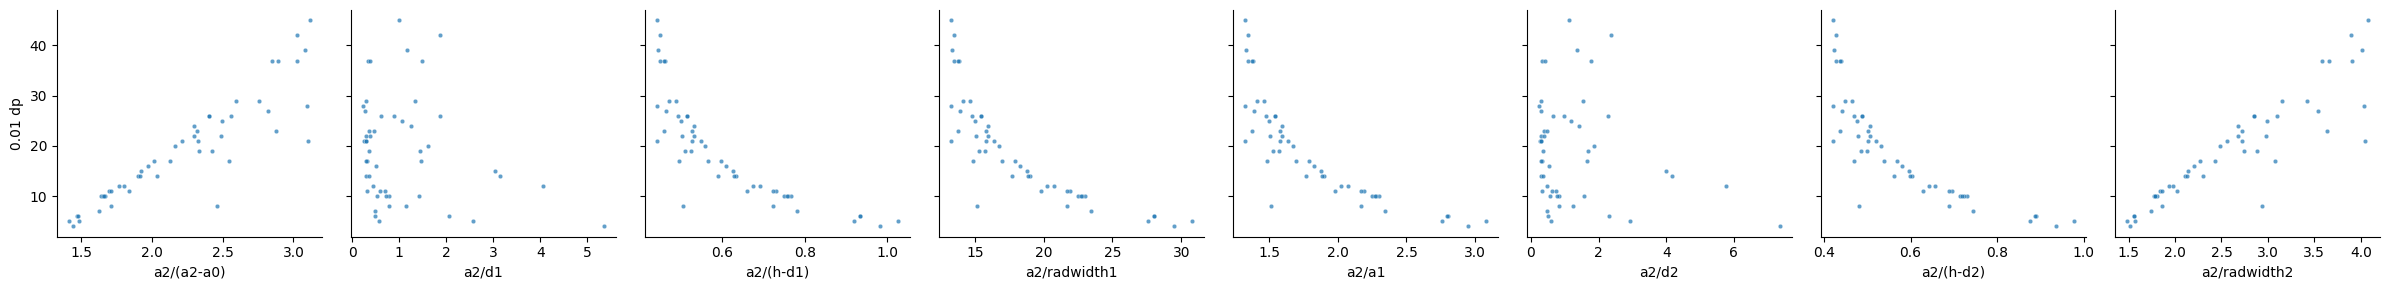

In [8]:
y_funcs = {# "0.01 am" : (lambda data_dict, m0 : data_dict[m0]["convergence point 0.01 am"])}#,
           "0.01 dp" : (lambda data_dict, m0 : data_dict[m0]["convergence point 0.01 dp"])}

suspects = hist_prob_sets[4]
count = 0
plot_fs = {}
for func_label in dim0s.keys():
  variable_vals = [dim0s[func_label](suspect, m0) for suspect in suspects for m0 in suspect["m0s"]]
  min_v, max_v = min(variable_vals), max(variable_vals)
  if abs(max_v-min_v)/max_v > 0.00001:
    plot_fs[func_label] = dim0s[func_label]
    count += 1
    if count == 10:
      plot_relation_grid(suspects, plot_fs, y_funcs)
      count, plot_fs = 0, {}
if count != 0:
  plot_relation_grid(suspects, plot_fs, y_funcs)

Investigate damping trends against two ratios.

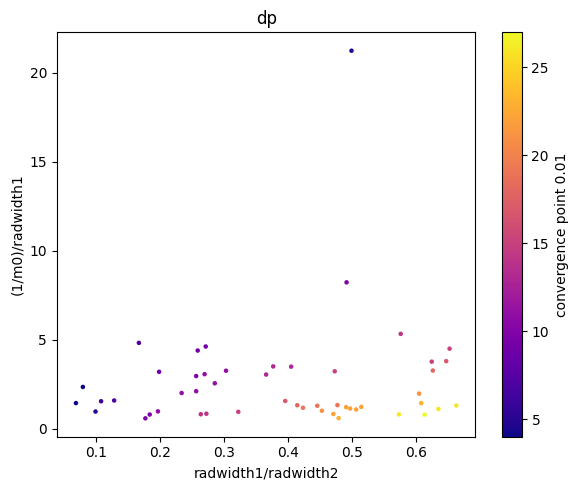

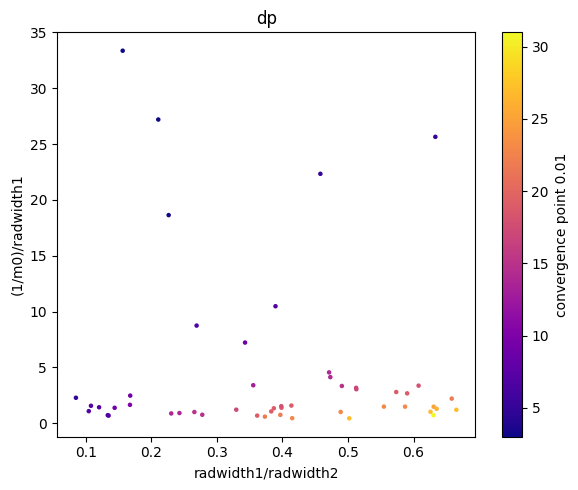

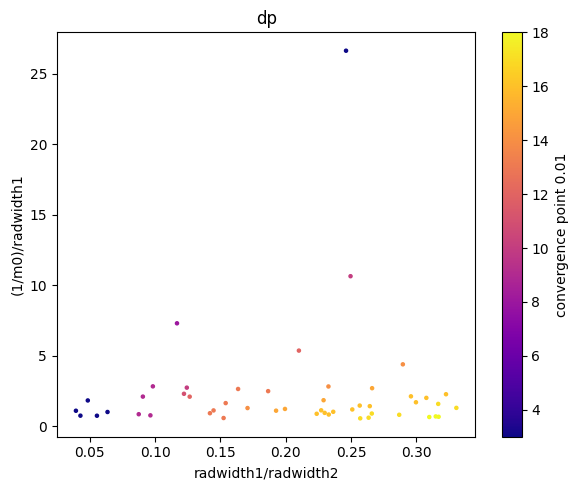

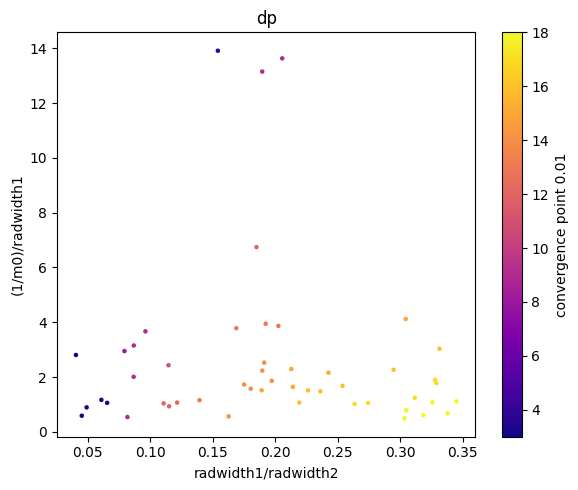

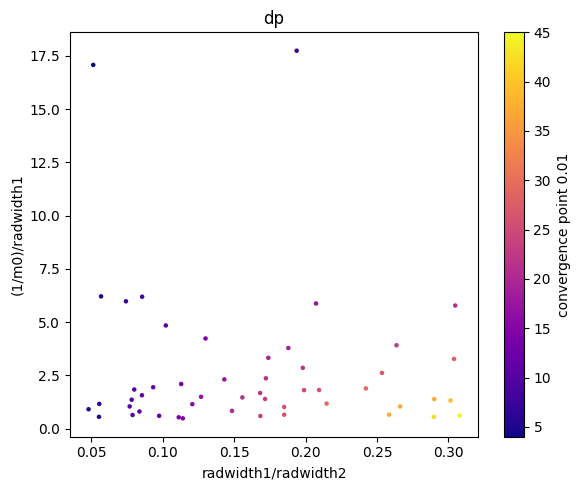

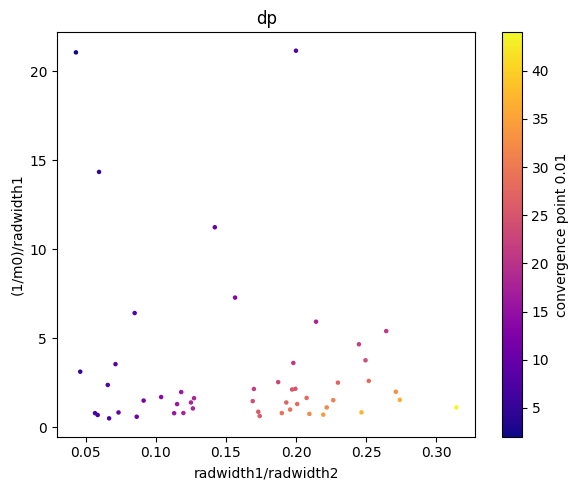

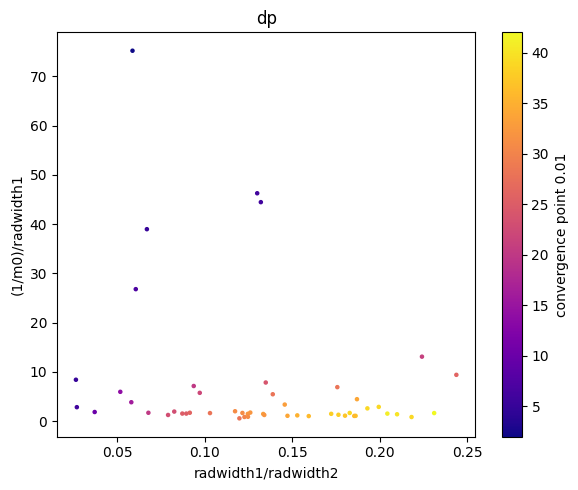

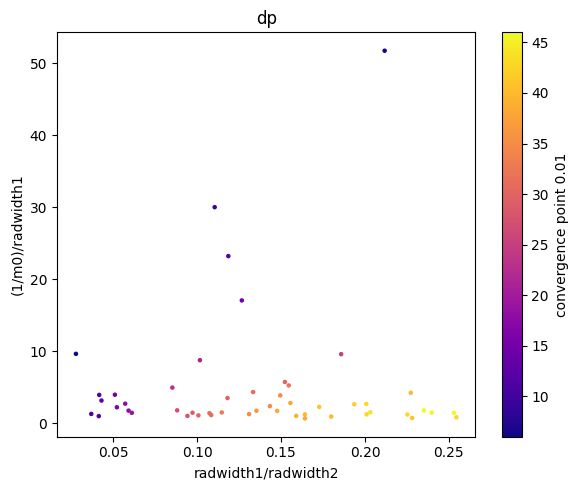

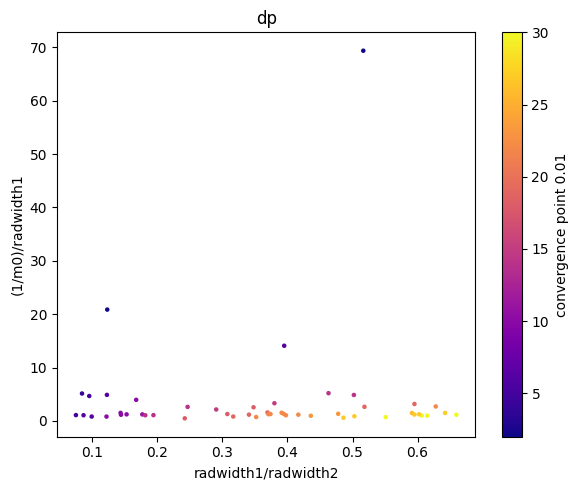

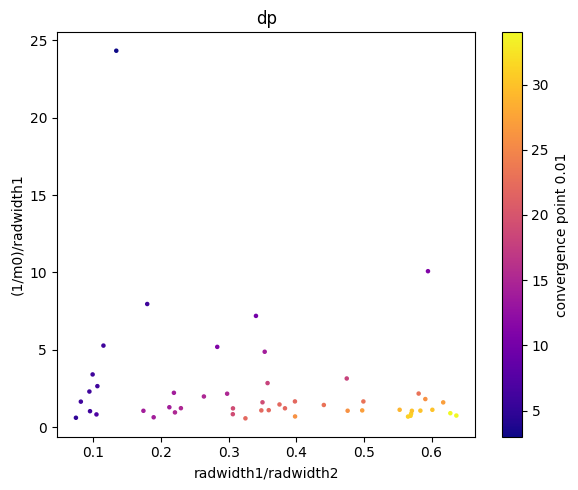

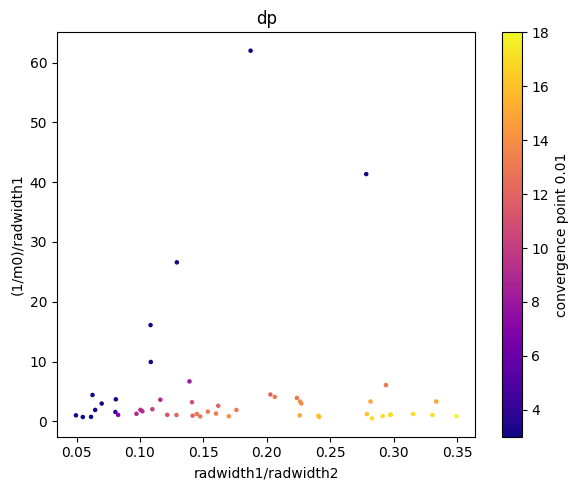

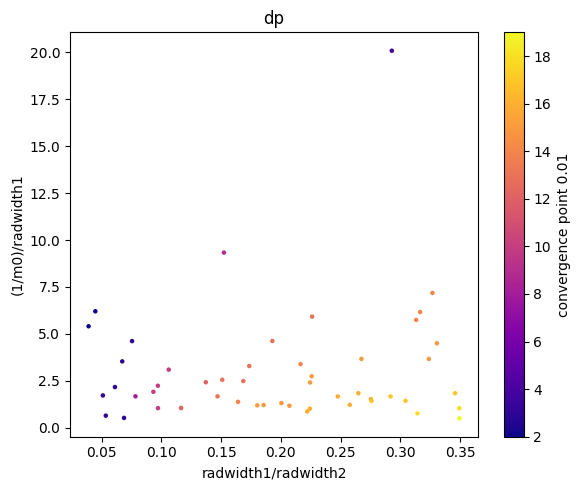

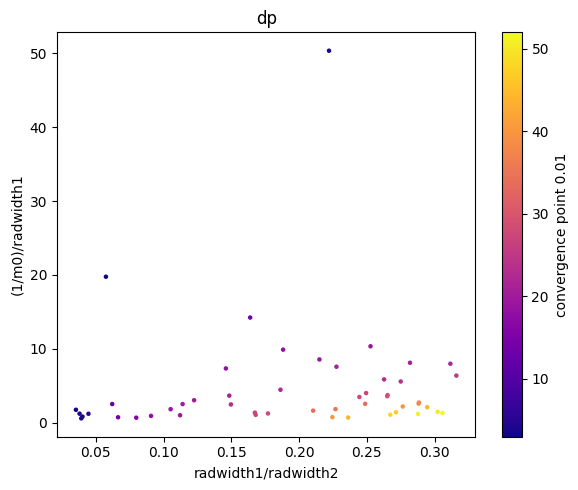

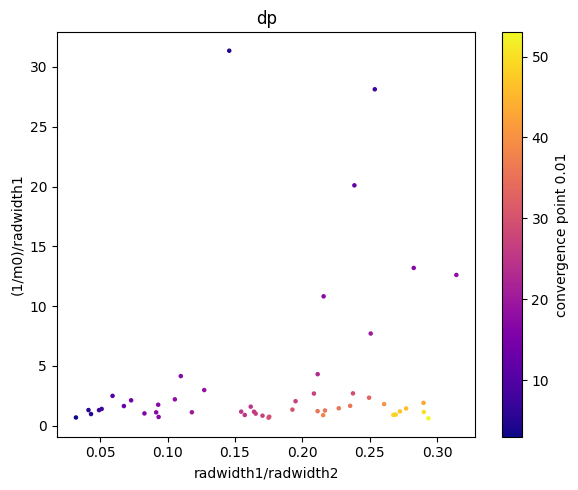

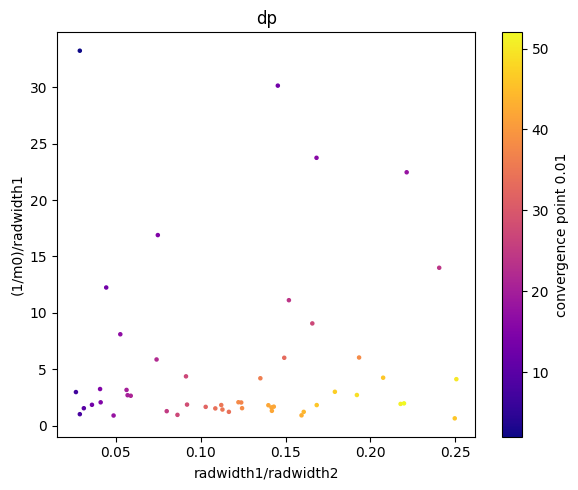

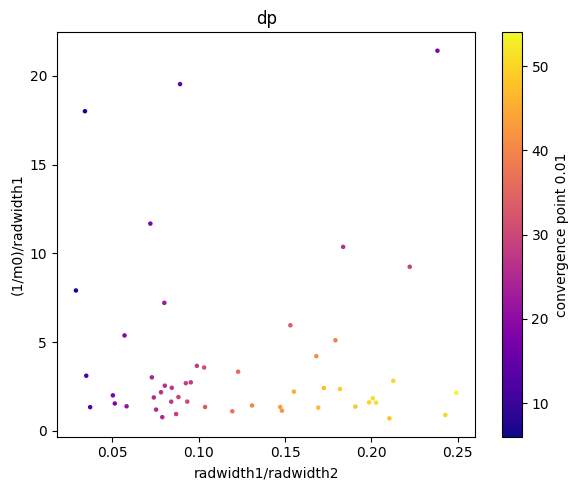

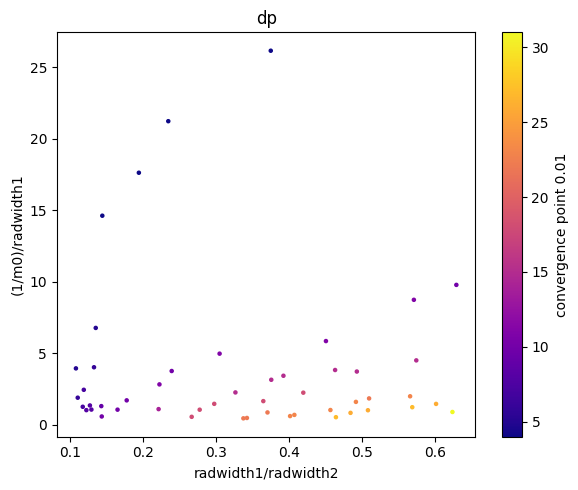

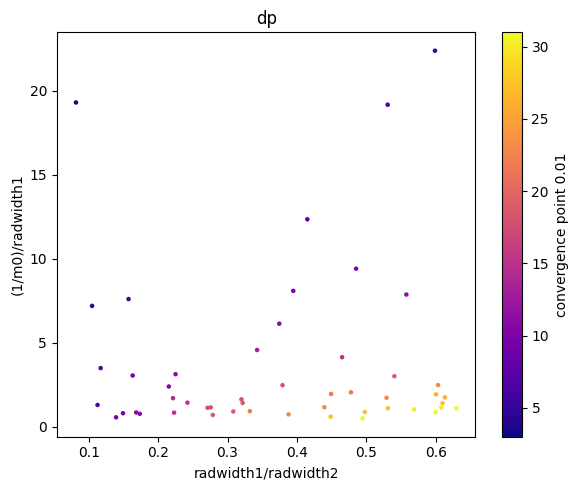

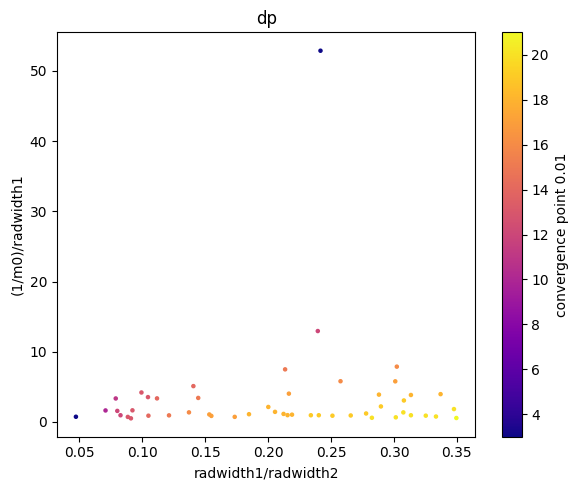

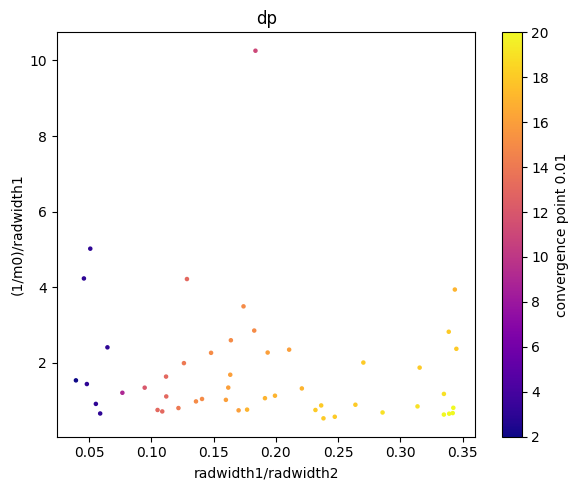

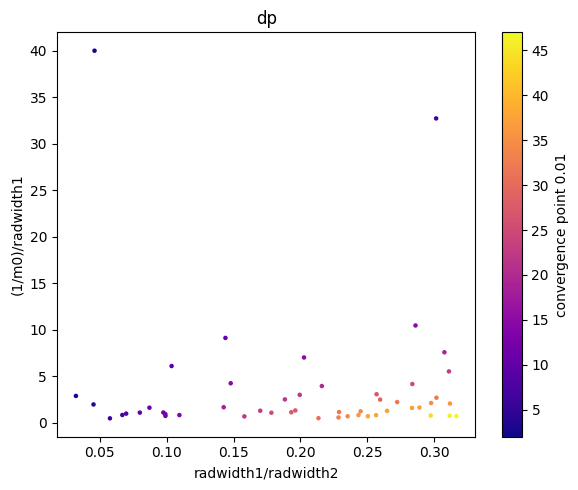

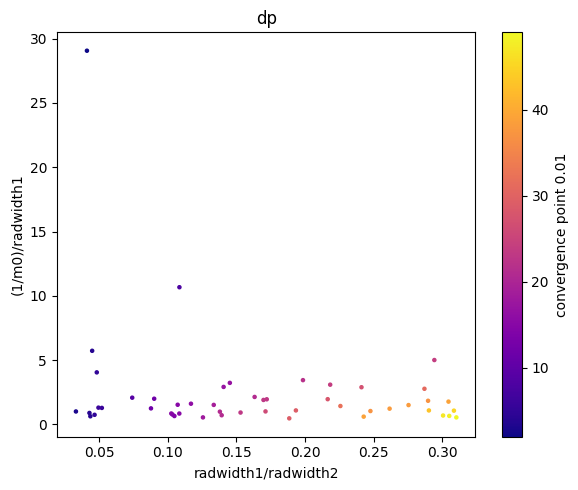

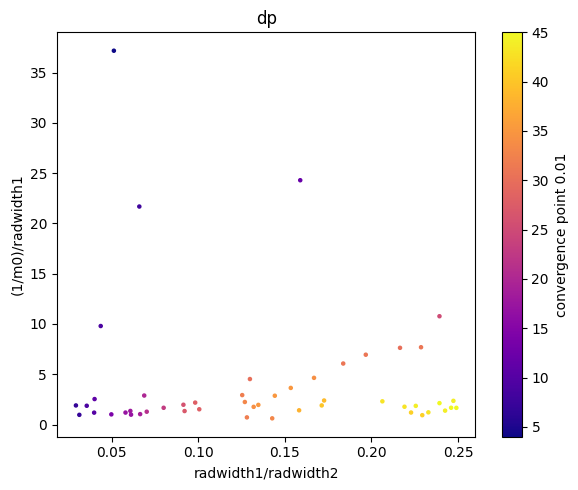

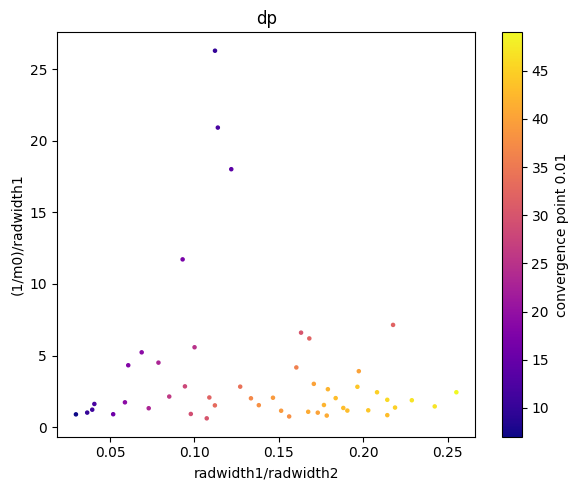

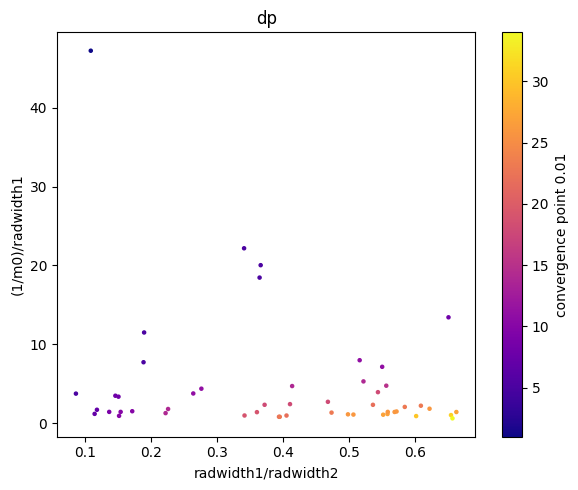

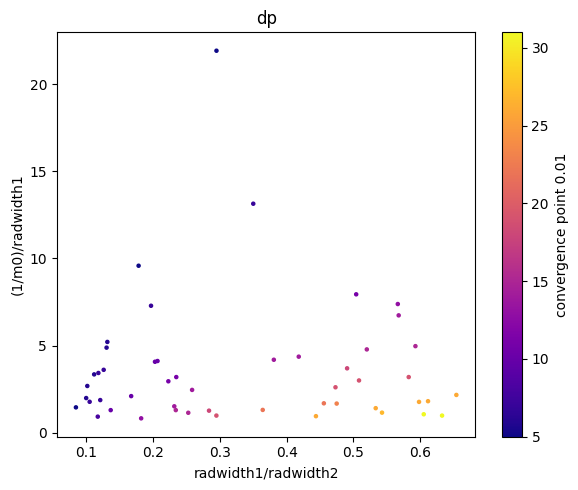

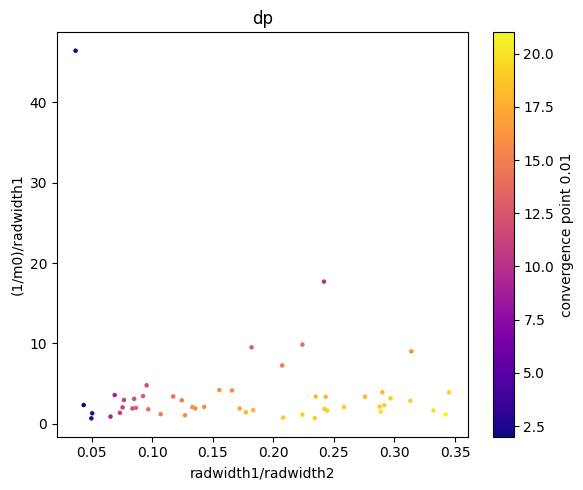

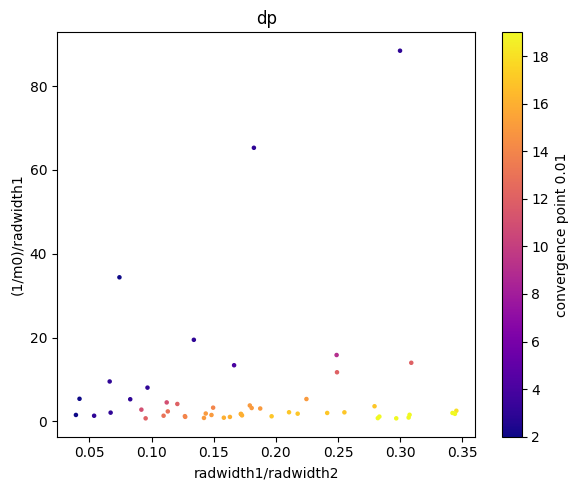

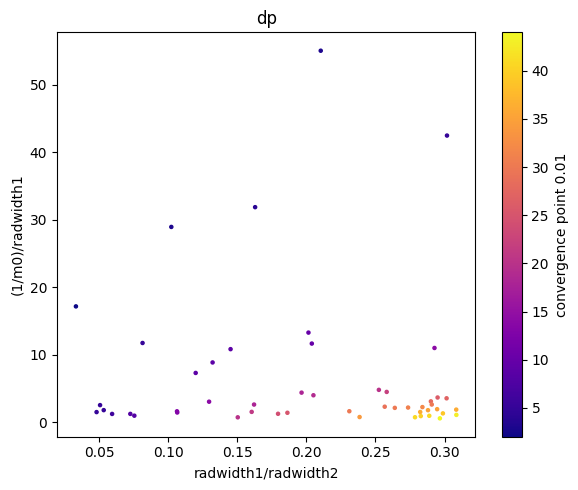

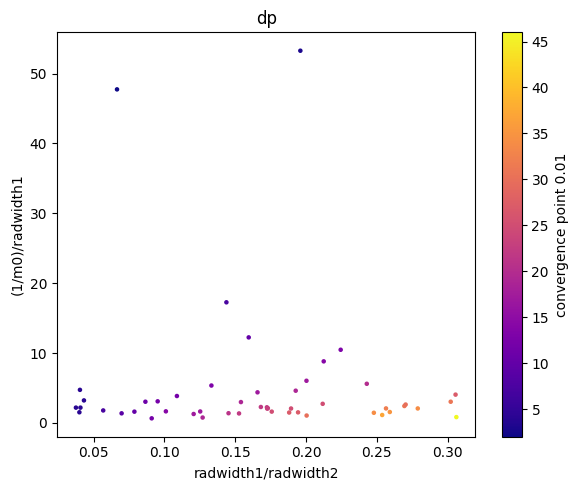

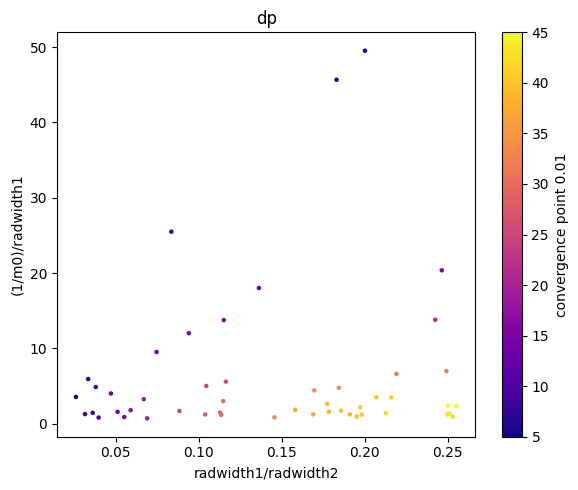

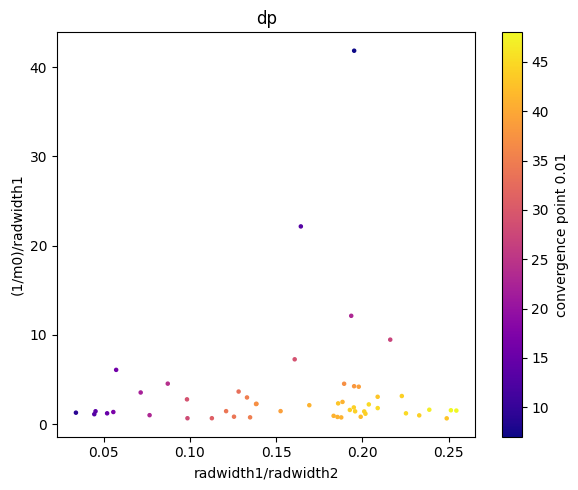

In [9]:
for prob_set in hist_prob_sets:
  plot_hydros_against_2(prob_set, "dp", 0.01, dim0s["radwidth1/radwidth2"], dim0s["(1/m0)/radwidth1"], "radwidth1/radwidth2", "(1/m0)/radwidth1")

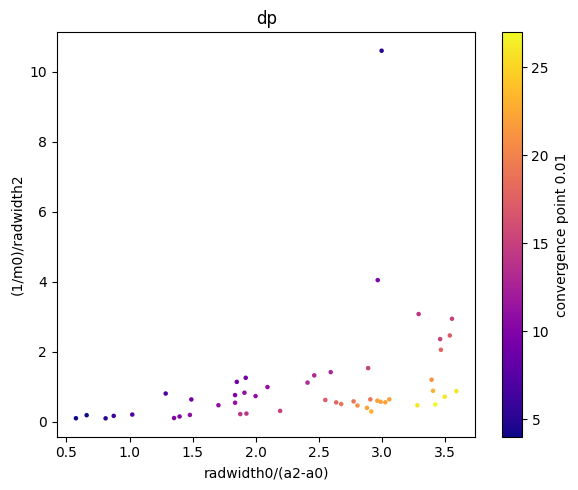

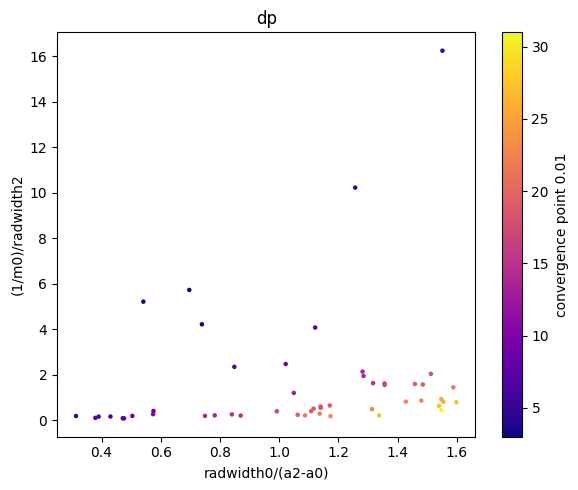

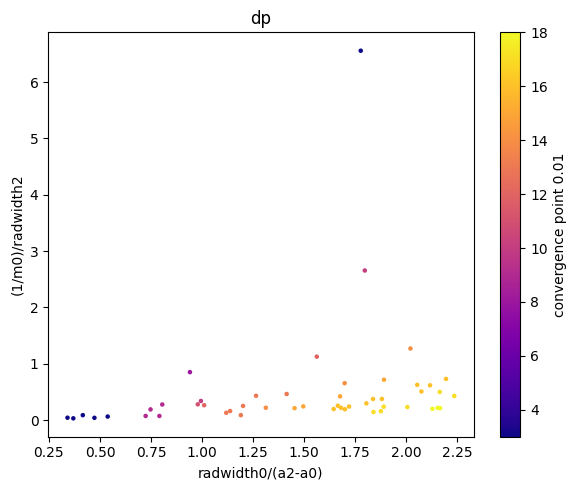

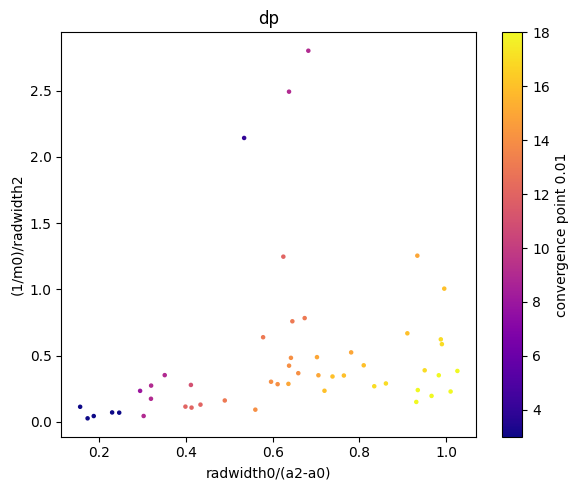

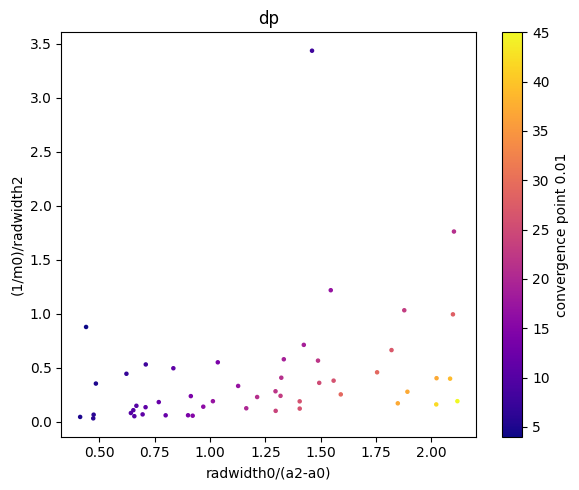

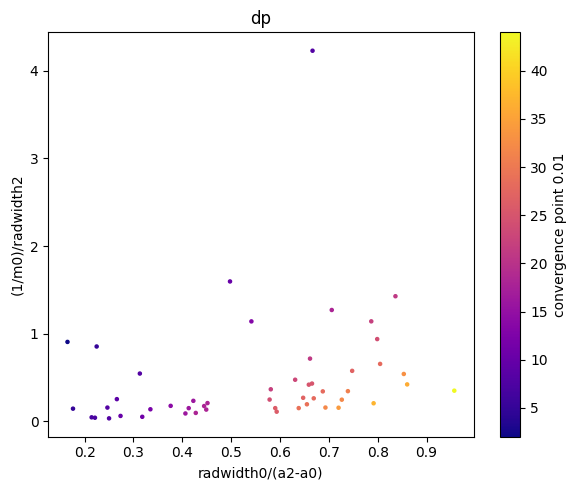

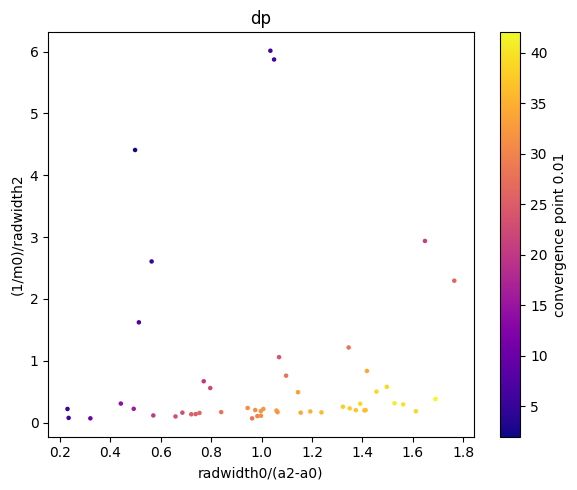

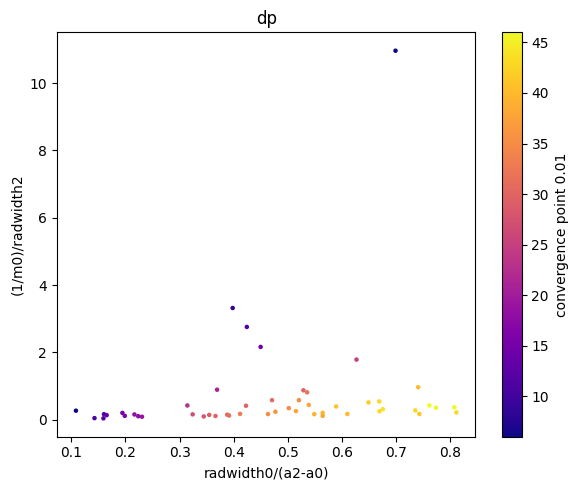

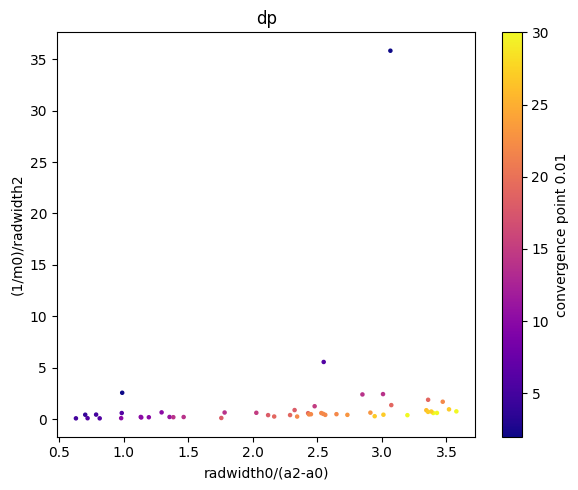

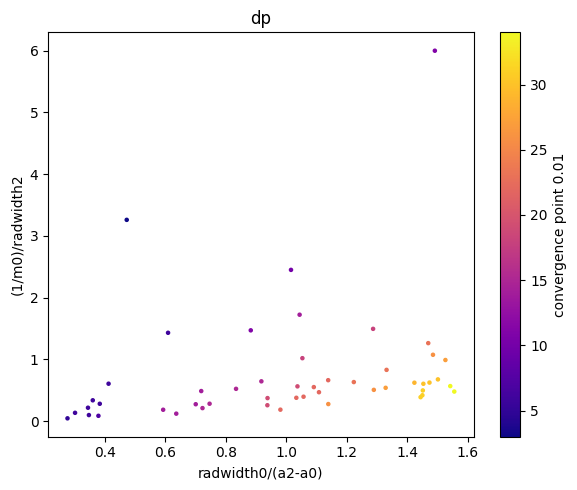

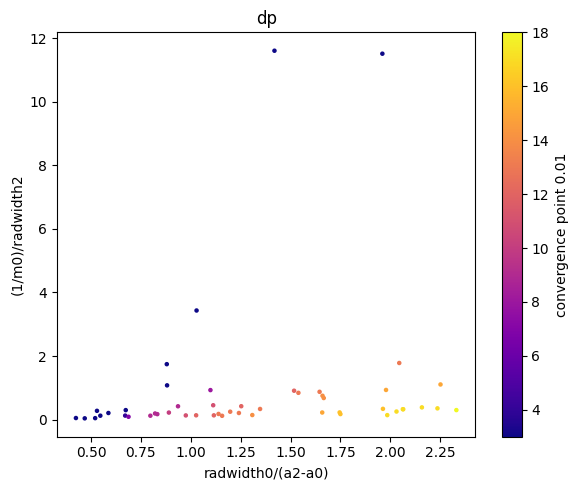

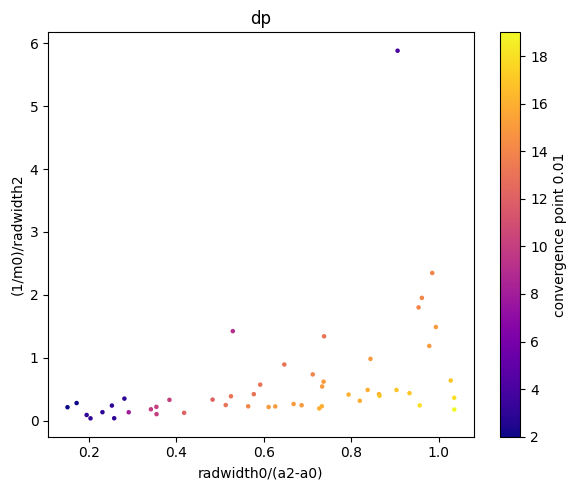

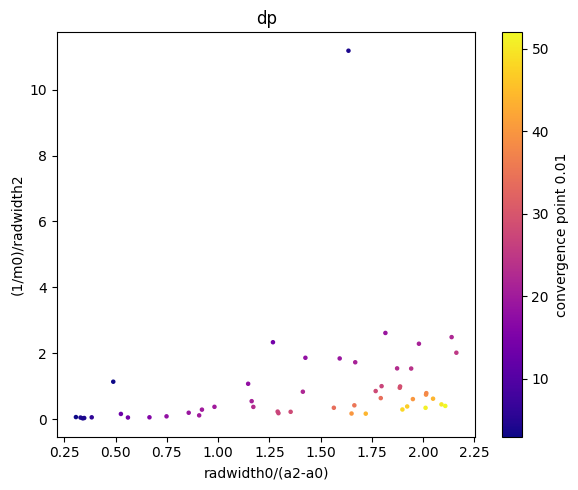

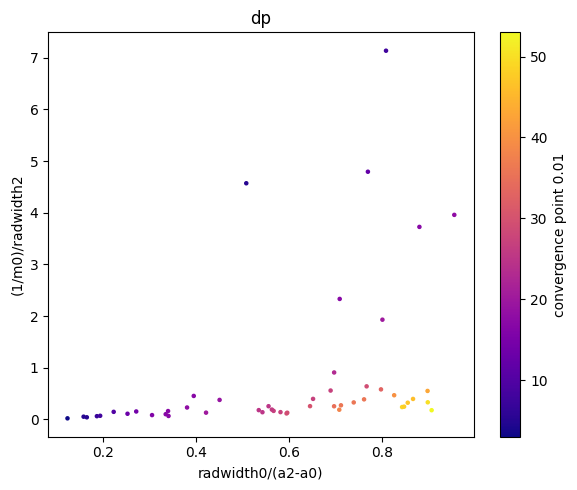

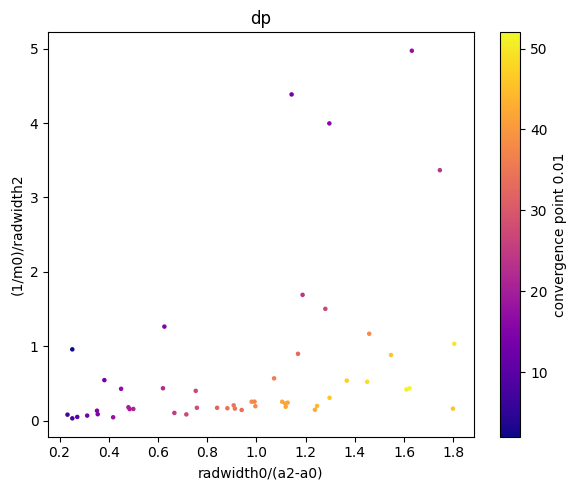

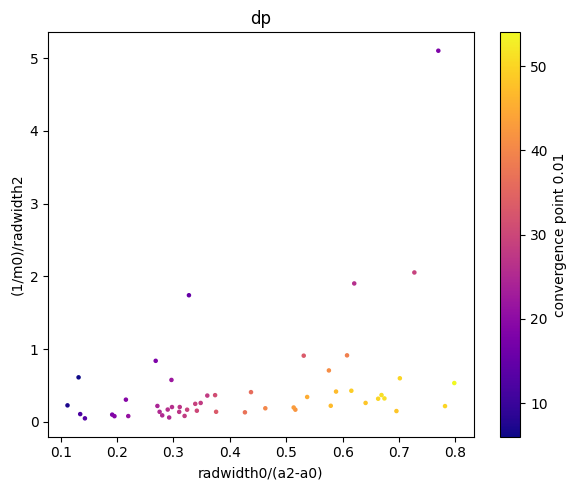

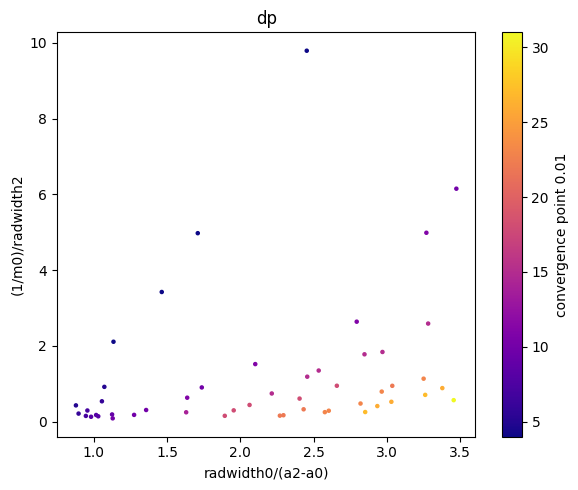

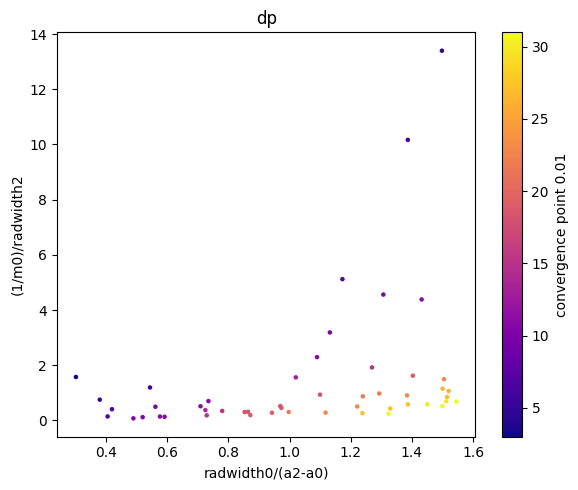

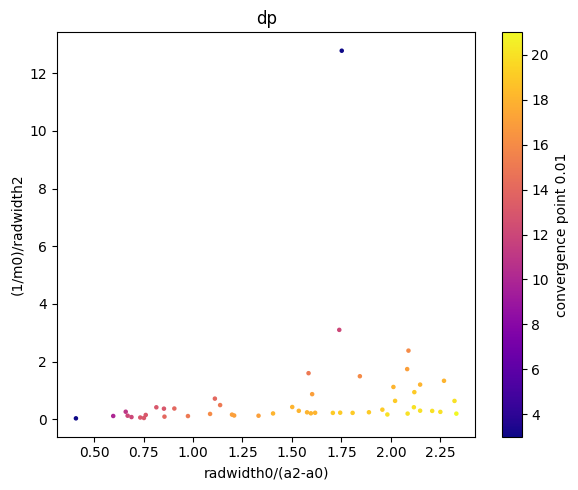

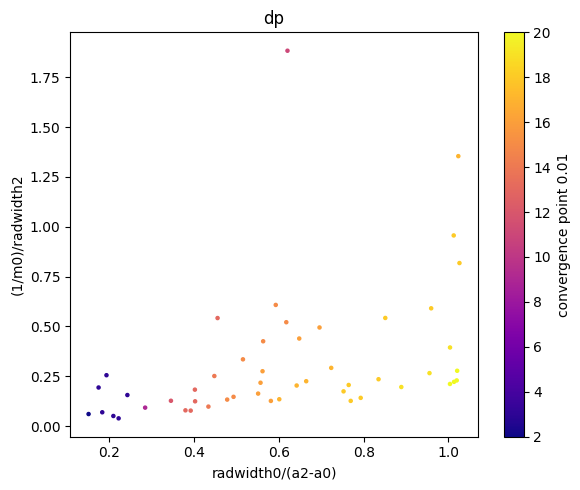

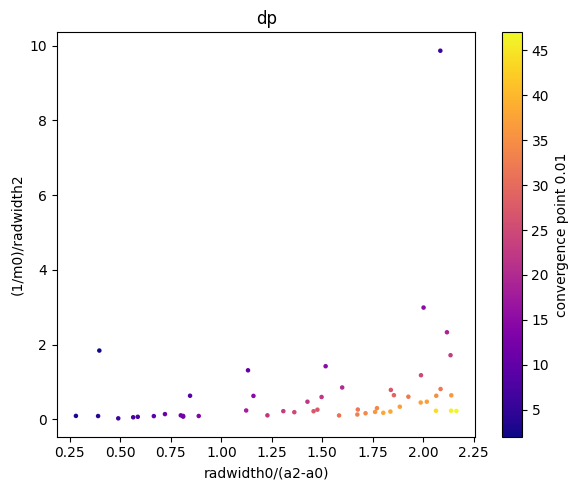

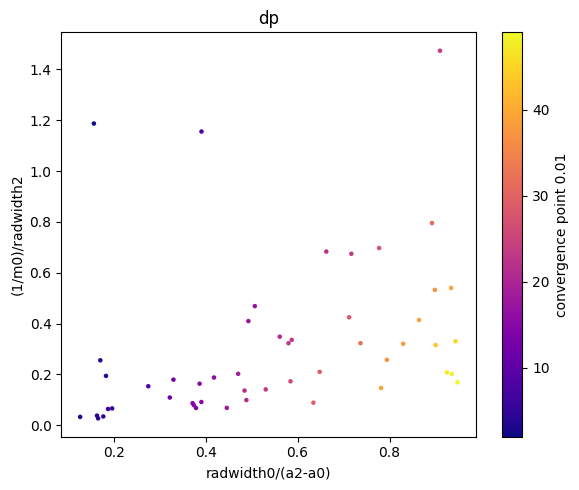

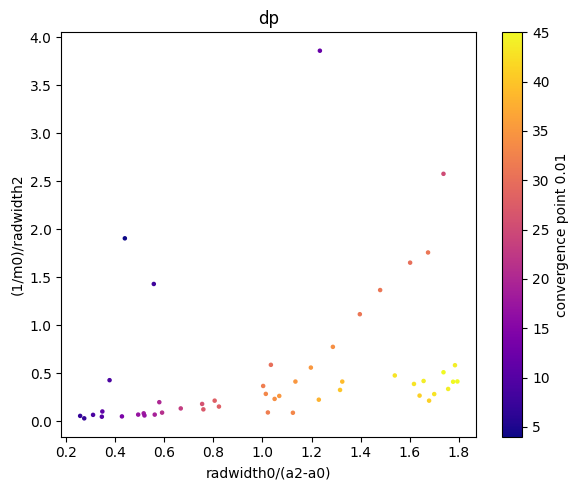

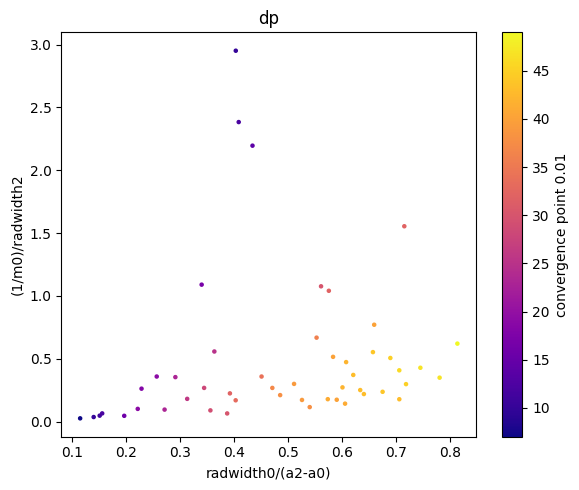

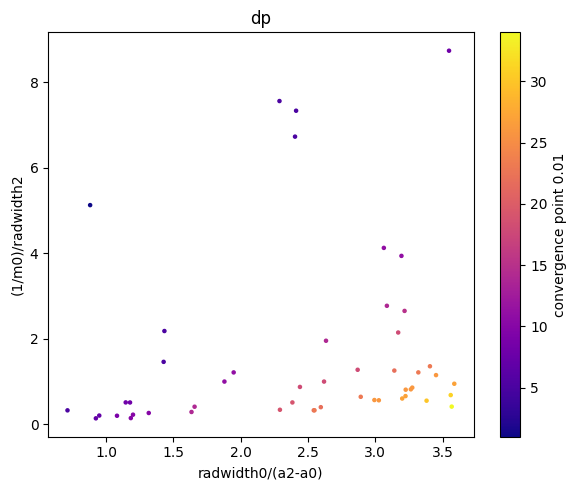

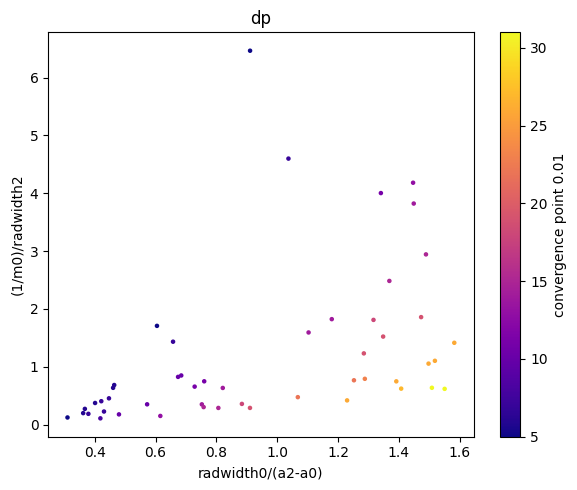

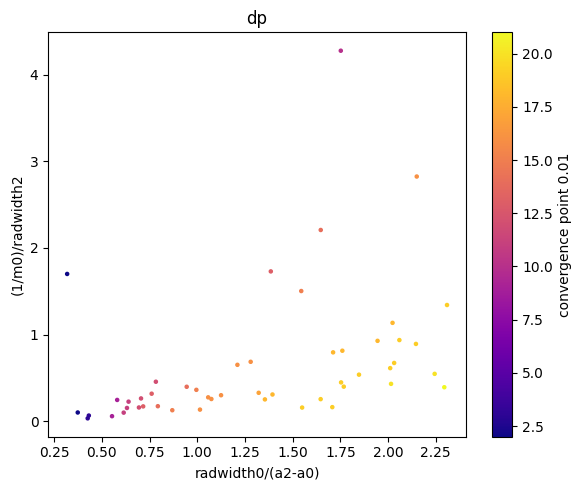

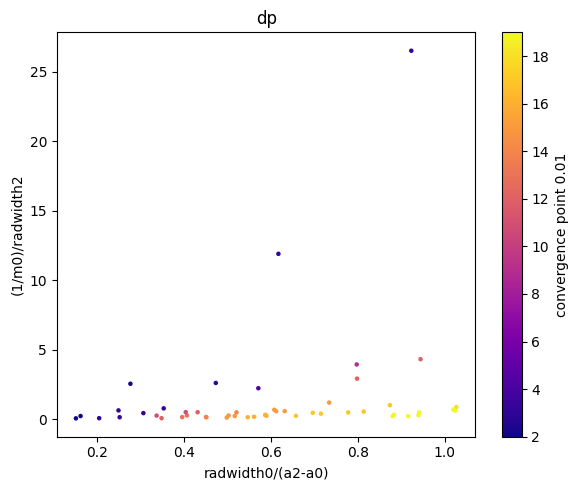

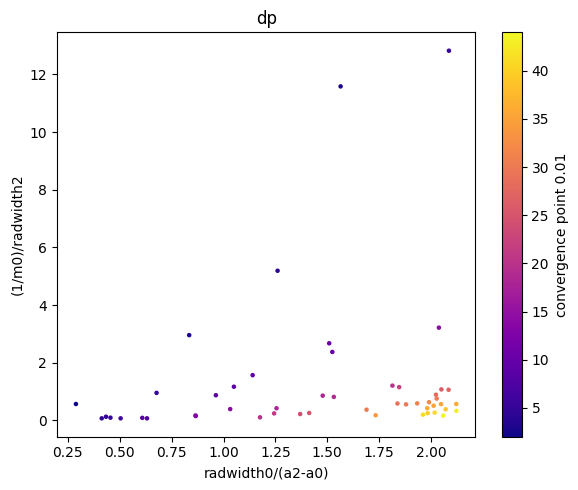

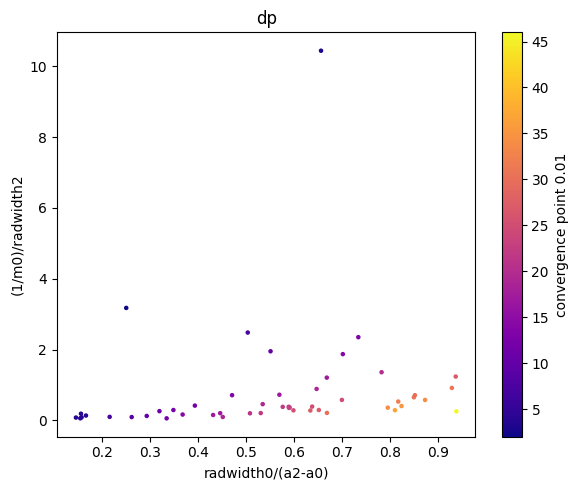

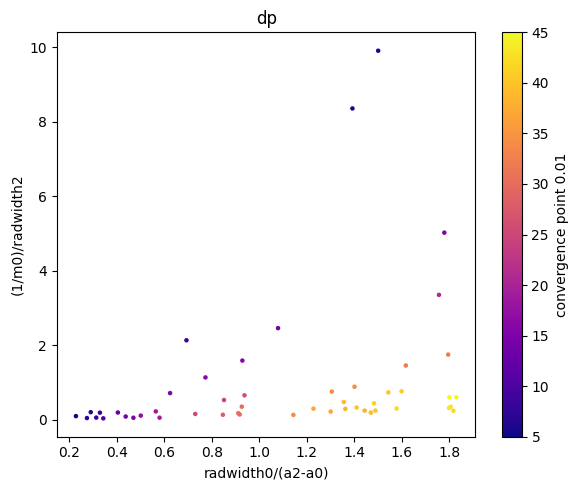

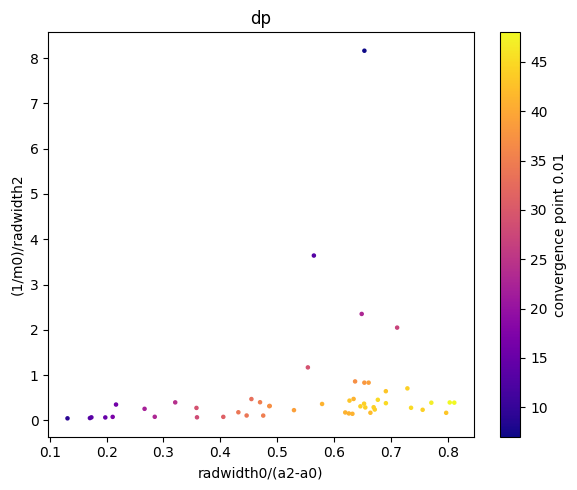

In [10]:
for prob_set in hist_prob_sets:
  plot_hydros_against_2(prob_set, "dp", 0.01, dim0s["radwidth0/(a2-a0)"], dim0s["(1/m0)/radwidth2"], "radwidth0/(a2-a0)", "(1/m0)/radwidth2")

Check variables selected for damping for both added mass and damping.

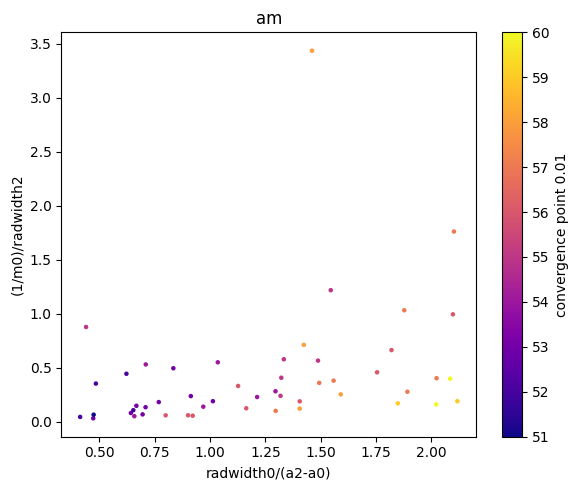

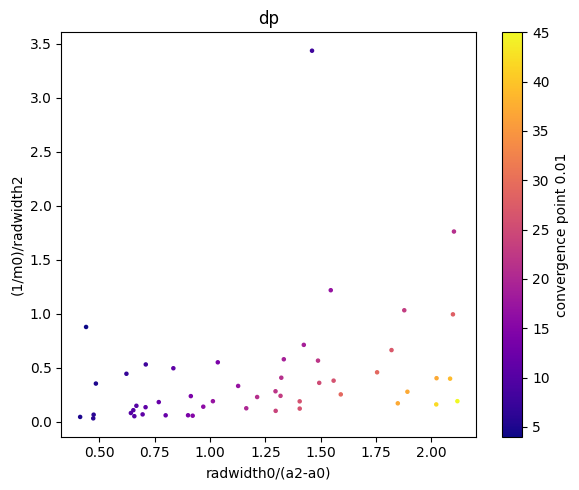

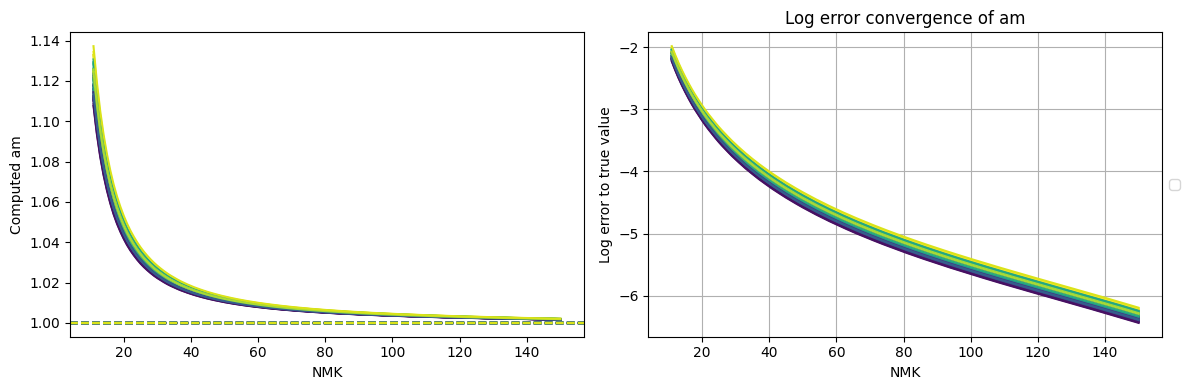

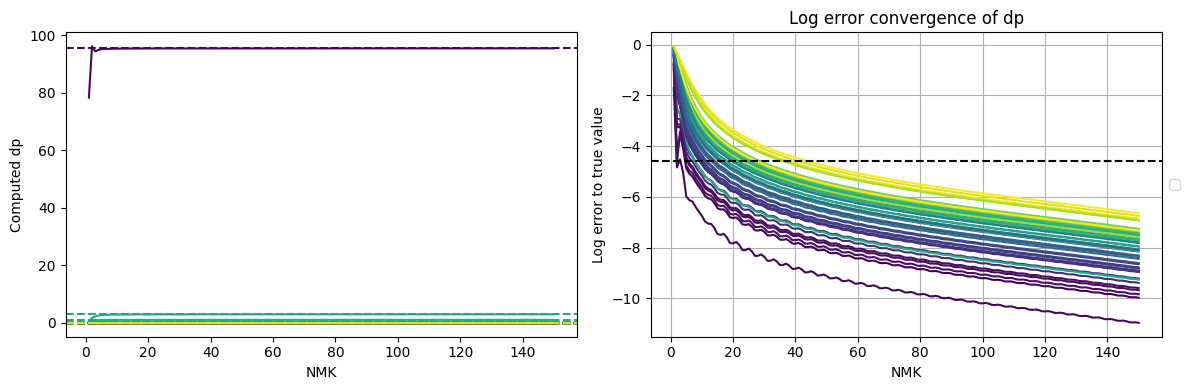

In [13]:
wide_hists = [hist_prob_sets[i] for i in range(32) if i%8>3]
plot_hydros_against_2(suspects, "am", 0.01, dim0s["radwidth0/(a2-a0)"], dim0s["(1/m0)/radwidth2"], "radwidth0/(a2-a0)", "(1/m0)/radwidth2")
plot_hydros_against_2(suspects, "dp", 0.01, dim0s["radwidth0/(a2-a0)"], dim0s["(1/m0)/radwidth2"], "radwidth0/(a2-a0)", "(1/m0)/radwidth2")
data = many_data_dicts_to_convergence_plot_data(suspects)
colors = color_by_f_value(dim0s["radwidth0/(a2-a0)"], suspects)
plot_set_convergence_and_log(data, "am", colors = colors, scale = True, error = 0.01,
                            nmk_max = 150, show_error = False, trunc = 10)
plot_set_convergence_and_log(data, "dp", colors = colors, scale = False, error = 0.01,
                            nmk_max = 150, show_error = True, trunc = 0)